# Marketing Campaign Data Cleaning

## Objective

This notebook cleans and standardizes the raw marketing campaign dataset based on the data-quality issues identified during profiling.

The cleaning process follows:

**Evidence → Decision → Transformation → Validation**

The raw dataset is preserved, while all transformations are performed on a working copy.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import re
df = pd.read_csv("marketing_campaign_data_messy.csv")

df_clean = df.copy()

In [ ]:
df_clean.head()

,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
0,CMP-00001,Q4_Summer_CMP-00001,2023-11-24 00:00:00,2023-12-13,TikTok,16795,197,$102.82,20.0,Y,NaN,TI
1,CMP-00002,Q1_Launch_CMP-00002,2023-05-06 00:00:00,2023-05-12,Facebook,1860,30,24.33,1.0,0,NaN,FA
2,CMP-00003,Q3_Winter_CMP-00003,2023-12-13 00:00:00,2023-12-20,Email,77820,843,1323.39,51.0,No,NaN,EM
3,CMP-00004,Q1_BlackFriday_CMP-00004,2023-10-30,2023-11-03,TikTok,55886,2019,2180.38,135.0,True,NaN,TI
4,CMP-00005,Q2_Winter_CMP-00005,2023-04-22 00:00:00,2023-04-23,Facebook,7265,169,252.44,30.0,Yes,NaN,FA


In [ ]:
df_clean.tail()

,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
2015,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.0,1,NaN,TI
2016,CMP-01255,Q4_Summer_CMP-01255,2023-09-01 00:00:00,2023-09-26,Google Ads,20097,897,1641.0,162.0,0,NaN,GO
2017,CMP-01050,Q2_Launch_CMP-01050,2023-02-09 00:00:00,2023-02-21,Instagram,33254,1117,883.82,214.0,0,NaN,IN
2018,CMP-01118,Q4_Winter_CMP-01118,2023-03-30 00:00:00,2023-04-27,Facebook,68728,2960,4198.5,591.0,Yes,NaN,FA
2019,CMP-01554,Q4_Launch_CMP-01554,2023-06-26 00:00:00,2023-07-09,Email,96402,1090,1315.59,66.0,Y,NaN,EM


In [ ]:
df_clean.shape

(2020, 12)

In [ ]:
df_clean.describe()

,Impressions,Clicks,Conversions,Clicks
count,2020.000000,2020.000000,1820.000000,40.000000
mean,49839.896040,1500.744059,186.085714,54856.200000
std,28579.637473,1084.765654,160.129172,30552.773369
min,1055.000000,11.000000,0.000000,2508.000000
25%,25033.500000,650.750000,68.000000,30164.750000
50%,50097.500000,1245.000000,142.000000,57707.500000
75%,74784.250000,2185.250000,257.000000,81497.500000
max,99875.000000,4812.000000,943.000000,99483.000000


In [ ]:
df_clean.info()
# Findings from df.info():
# - Total entries: 2020
# - Columns: 12
# - Data types: There are 8 object columns, 2 int64 columns, and 2 float64 columns.
# - Missing values:
#   - 'Channel' has 1919 non-null values, indicating 101 missing values.
#   - 'Conversions' has 1820 non-null values, indicating 200 missing values.
#   - The second 'Clicks' column (index 10) has only 40 non-null values, indicating 1980 missing values, confirming it is largely empty and likely a duplicate.
# - Data type considerations:
#   - 'Start_Date', 'End_Date', 'Spend', and 'Active' are object types but should likely be datetime or numeric/boolean types, requiring conversion.
#   - 'Campaign_ID', 'Campaign_Name', and 'Campaign_Tag' are object types, which is appropriate for categorical/identifier data.
# - Memory usage: 189.5+ KB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0    Campaign_ID   2020 non-null   object 
 1   Campaign_Name  2020 non-null   object 
 2   Start_Date     2020 non-null   object 
 3   End_Date       2020 non-null   object 
 4   Channel        1919 non-null   object 
 5   Impressions    2020 non-null   int64  
 6   Clicks         2020 non-null   int64  
 7   Spend          2020 non-null   object 
 8   Conversions    1820 non-null   float64
 9   Active         2020 non-null   object 
 10  Clicks         40 non-null     float64
 11  Campaign_Tag   2020 non-null   object 
dtypes: float64(2), int64(2), object(8)
memory usage: 189.5+ KB


In [ ]:
df_clean.isna().sum().sort_values(ascending=False)

,0
Clicks,1980
Conversions,200
Channel,101
Campaign_ID,0
End_Date,0
Start_Date,0
Campaign_Name,0
Impressions,0
Spend,0
Clicks,0


In [ ]:
#Checking the name column inconsistency and duplicates
df_clean.columns

Index([' Campaign_ID ', 'Campaign_Name', 'Start_Date', 'End_Date', 'Channel',
       'Impressions', 'Clicks ', 'Spend', 'Conversions', 'Active', 'Clicks',
       'Campaign_Tag'],
      dtype='object')

In [ ]:
# Renaming the both clicks columns for consistency.
df_clean = df_clean.rename(columns={
    "Clicks ": "clicks_1",
    "Clicks": "clicks_2"
})

In [ ]:
#Checking inconsistencies in column headers
print(df_clean.columns.tolist())

#Fixing headers
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)
print(df_clean.columns)

[' Campaign_ID ', 'Campaign_Name', 'Start_Date', 'End_Date', 'Channel', 'Impressions', 'clicks_1', 'Spend', 'Conversions', 'Active', 'clicks_2', 'Campaign_Tag']
Index(['campaign_id', 'campaign_name', 'start_date', 'end_date', 'channel',
       'impressions', 'clicks_1', 'spend', 'conversions', 'active', 'clicks_2',
       'campaign_tag'],
      dtype='object')


In [ ]:
# Checking the number of unique campaigns run throughout 2023 - 2024.(Only 20 being repeated, need to inspect). Identifying the duplicate campaigns
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique campaign IDs:", df[" Campaign_ID "].nunique())

Exact duplicate rows: 19
Unique campaign IDs: 2000


In [ ]:
#Inspecting the duplicate 20 campaigns
duplicate_ids = df_clean[
    df_clean["campaign_id"].duplicated(keep=False)
].sort_values("campaign_id")

display(duplicate_ids)

,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks_1,spend,conversions,active,clicks_2,campaign_tag
184,CMP-00185,Q3_Launch_CMP-00185,2023-08-03 00:00:00,2023-08-27,Facebok,56016,1728,1890.33,128.0,No,NaN,FA
2014,CMP-00185,Q3_Launch_CMP-00185,2023-08-03 00:00:00,2023-08-27,Facebok,56016,1728,1890.33,128.0,No,NaN,FA
387,CMP-00388,Q1_Summer_CMP-00388,2023-06-20 00:00:00,2023-06-25,TikTok,57958,2328,$2135.23,280.0,Y,NaN,TI
2013,CMP-00388,Q1_Summer_CMP-00388,2023-06-20 00:00:00,2023-06-25,TikTok,57958,2328,$2135.23,280.0,Y,NaN,TI
399,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.0,1,NaN,TI
2015,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.0,1,NaN,TI
438,CMP-00439,Q1_Launch_CMP-00439,2023-08-03 00:00:00,2023-08-27,Google Ads,88235,3182,5093.82,385.0,1,NaN,GO
2010,CMP-00439,Q1_Launch_CMP-00439,2023-08-03 00:00:00,2023-08-27,Google Ads,88235,3182,5093.82,385.0,1,NaN,GO
2011,CMP-01028,Q4_Summer_CMP-01028,2023-12-24 00:00:00,2024-01-05,TikTok,54441,2158,$2422.76,252.0,Yes,NaN,TI
1027,CMP-01028,Q4_Summer_CMP-01028,2023-12-24 00:00:00,2024-01-05,TikTok,54441,2158,$2422.76,252.0,Yes,NaN,TI


In [ ]:
# Columns used to compare campaign records
comparison_cols = [
    col for col in df_clean.columns
    if col.lower().strip() != "index"
]

# Count distinct versions of each repeated campaign
duplicate_audit = (
    df_clean[df_clean["campaign_id"].duplicated(keep=False)]
    .groupby("campaign_id")[comparison_cols]
    .apply(lambda group: len(group.drop_duplicates()))
    .reset_index(name="distinct_versions")
)

duplicate_audit["duplicate_type"] = duplicate_audit[
    "distinct_versions"
].map({
    1: "Exact duplicate",
}).fillna("Conflicting duplicate")

display(duplicate_audit)

,campaign_id,distinct_versions,duplicate_type
0,CMP-00185,1,Exact duplicate
1,CMP-00388,1,Exact duplicate
2,CMP-00400,1,Exact duplicate
3,CMP-00439,1,Exact duplicate
4,CMP-01028,1,Exact duplicate
5,CMP-01050,1,Exact duplicate
6,CMP-01064,1,Exact duplicate
7,CMP-01118,1,Exact duplicate
8,CMP-01200,1,Exact duplicate
9,CMP-01255,1,Exact duplicate


In [ ]:
#Checking the conflicting duplicate.

display(
    df_clean[df_clean["campaign_id"] == "CMP-01377"]
)

,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks_1,spend,conversions,active,clicks_2,campaign_tag
1376,CMP-01377,Q1_Winter_CMP-01377,2023-12-21 00:00:00,2023-12-29,E-mail,87143,2204,2649.14,391.0,Yes,NaN,INVALID
2008,CMP-01377,Q1_Winter_CMP-01377,2023-12-21 00:00:00,2023-12-29,E-mail,87143,2204,2649.14,391.0,Yes,NaN,E-


In [ ]:
# Preserving the original tag before making corrections
df_clean["campaign_tag_raw"] = df_clean["campaign_tag"]

# Applying the documented mapping to this specific campaign
df_clean.loc[
    df_clean["campaign_id"] == "CMP-01377",
    "campaign_tag"
] = "EM"

In [ ]:
# Verifying the rows before removing the duplicate campaigns.
print("Rows before:", len(df_clean))
print("Unique campaigns:", df_clean["campaign_id"].nunique())
print("Duplicate rows:", df_clean["campaign_id"].duplicated().sum())

Rows before: 2020
Unique campaigns: 2000
Duplicate rows: 20


In [ ]:
# Removing the duplicated records
df_clean = df_clean.drop_duplicates(
    subset="campaign_id",
    keep="first"
 ).copy()

In [ ]:
# Verifying the rows after removing the duplicate campaigns.
print("Rows after:", len(df_clean))
print("Unique campaigns:", df_clean["campaign_id"].nunique())

Rows after: 2000
Unique campaigns: 2000


Duplicate Campaign IDs: 20 campaign IDs appeared more than once. A record-level comparison showed that the duplicated rows contained identical values across all columns, confirming them as duplicate records rather than multiple observations of the same campaign. One copy of each duplicate record was retained.

`Campaign_ID - CMP-01377` - The duplicate campaign records have the same campaign information, and the only discrepancy is Campaign_Tag. Based on the observed Campaign_Tag–Channel relationship, E- is consistent with Email, while INVALID is inconsistent. Therefore, the two rows represent the same campaign record, and retaining one record is appropriate.

In [ ]:
# Comparing the two Clicks columns

comparison = df_clean[["clicks_1", "clicks_2"]]

comparison.head(20)

,clicks_1,clicks_2
0,197,NaN
1,30,NaN
2,843,NaN
3,2019,NaN
4,169,NaN
5,2643,NaN
6,1135,NaN
7,1173,NaN
8,1179,NaN
9,1153,NaN


In [ ]:
different_clicks = comparison[
    comparison["clicks_1"] != comparison["clicks_2"]
]

different_clicks.shape

(2000, 2)

In [ ]:
both_present = comparison[
    comparison["clicks_1"].notna() &
    comparison["clicks_2"].notna()
]

(both_present["clicks_1"] == both_present["clicks_2"]).mean()

np.float64(0.0)

In [ ]:
# The second Clicks column is largely missing and does not provide
# a reliable independent measure of clicks as per the profiling it also violates the business rule.

df_clean = df_clean.drop(columns="clicks_2")

In [ ]:
#checking if the "clicks_2" column still exist
df_clean.columns

Index(['campaign_id', 'campaign_name', 'start_date', 'end_date', 'channel',
       'impressions', 'clicks_1', 'spend', 'conversions', 'active',
       'campaign_tag', 'campaign_tag_raw'],
      dtype='object')

Removed the duplicate `Clicks` columns with 40 nan values. Considering this data parsing issue with duplicates of the same column. The second Clicks column is largely missing and does not provide a reliable independent measure of clicks as per the profiling it also violates the business rule.

In [ ]:
# 1. Checking the mixed values in spend
print(df_clean['spend'].head(20))

# 2. Clean unwanted characters
df_clean['spend'] = (
    df_clean['spend']
    .astype(str)
    .str.replace(r'[^\d.,-]', '', regex=True)
    .str.replace(',', '', regex=False)
)

# 3. Converting text to numeric
df_clean['spend'] = pd.to_numeric(df_clean['spend'], errors='coerce')

# 4. Checking the datatype
print(df_clean['spend'].dtype)

# 5. Investigating negative values separately
print(df_clean.loc[df_clean['spend'] < 0, ['campaign_id', 'spend']])

0     $102.82
1       24.33
2     1323.39
3     2180.38
4      252.44
5     2697.03
6     1232.76
7       865.7
8     1046.18
9     1623.56
10     523.13
11    1267.69
12    5292.16
13    1464.72
14     139.18
15     1552.9
16    3147.37
17    3635.76
18    2933.59
19     353.99
Name: spend, dtype: object
float64
     campaign_id    spend
144    CMP-00145 -1407.54
407    CMP-00408 -1214.52
576    CMP-00577  -821.80
604    CMP-00605  -942.80
676    CMP-00677 -1640.88
817    CMP-00818 -1261.81
886    CMP-00887 -2162.50
924    CMP-00925  -648.30
1125   CMP-01126  -122.80
1142   CMP-01143   -20.05
1317   CMP-01318 -1197.93
1409   CMP-01410  -386.43
1418   CMP-01419  -938.20
1457   CMP-01458  -551.19
1559   CMP-01560  -647.64
1701   CMP-01702 -1058.27
1710   CMP-01711   -65.19
1897   CMP-01898 -2503.31
1935   CMP-01936 -1697.64


In [ ]:
#Checking the count of negative spend values
(df_clean['spend'] < 0).sum()

np.int64(19)

In [ ]:
df_clean["spend_analysis"] = df_clean["spend"].where(
    df_clean["spend"] >= 0,
    np.nan
)

# Findings on Negative Spend Values:

*   The previous cell identified several campaigns with negative values in the 'spend' column (e.g., `CMP-00145` with -140754, `CMP-01898` with -250331).
*   Negative spend values are typically not expected for advertising campaigns and likely indicate data entry errors or specific accounting adjustments that need clarification.
*   These outliers could significantly skew aggregated spend analyses and impact the accuracy of campaign performance metrics if not handled appropriately.
*   Further investigation is needed to understand the cause of these negative values and determine the best approach for correction (e.g., setting to zero, taking absolute value, or removing the records if they are invalid).

In [ ]:
# Inspecting the negative spend values

negative_spend = df_clean["spend"] < 0

print("Negative spend records:", negative_spend.sum())
print("Negative spend percentage:", negative_spend.mean()*100)

Negative spend records: 19
Negative spend percentage: 0.95


In [ ]:
# checking the spend values against other columns to locate any relation

df_clean.loc[
    negative_spend,
    ["campaign_id", "campaign_name", "start_date", "end_date", "spend", "impressions", "clicks_1", "conversions"]
].head(20)

,campaign_id,campaign_name,start_date,end_date,spend,impressions,clicks_1,conversions
144,CMP-00145,Q2_Summer_CMP-00145,2023-12-07 00:00:00,2023-12-14,-1407.54,51636,1859,270.0
407,CMP-00408,Q1_BlackFriday_CMP-00408,2023-05-21 00:00:00,2023-05-28,-1214.52,78575,2058,119.0
576,CMP-00577,Q4_Launch_CMP-00577,2023-06-30 00:00:00,2023-07-13,-821.80,90084,940,178.0
604,CMP-00605,Q2_BlackFriday_CMP-00605,2023-02-03 00:00:00,2023-02-25,-942.80,42555,515,57.0
676,CMP-00677,Q3_BlackFriday_CMP-00677,2023-10-15 00:00:00,2023-10-26,-1640.88,41262,1025,64.0
817,CMP-00818,Q1_Launch_CMP-00818,2023-09-05,2023-05-16,-1261.81,35816,1291,82.0
886,CMP-00887,Q4_Summer_CMP-00887,2023-07-29 00:00:00,2023-08-13,-2162.50,70836,2292,150.0
924,CMP-00925,Q4_Launch_CMP-00925,2023-02-28 00:00:00,2023-03-15,-648.30,23574,1054,104.0
1125,CMP-01126,Q1_Launch_CMP-01126,2023-11-11 00:00:00,2023-12-11,-122.80,12302,204,25.0
1142,CMP-01143,Q1_BlackFriday_CMP-01143,2023-11-10 00:00:00,2023-12-01,-20.05,1922,29,2.0


In [ ]:
df_clean.loc[
    negative_spend,
    ["conversions"]
].head(20)

,conversions
144,270.0
407,119.0
576,178.0
604,57.0
676,64.0
817,82.0
886,150.0
924,104.0
1125,25.0
1142,2.0


In [ ]:
df_clean.loc[negative_spend, "spend"].describe()

,spend
count,19.000000
mean,-1015.200000
std,678.882126
min,-2503.310000
25%,-1334.675000
50%,-942.800000
75%,-599.415000
max,-20.050000


In [ ]:
df_clean.loc[negative_spend,
       ["campaign_id", "campaign_name", "channel", "spend"]
].sort_values("spend")

,campaign_id,campaign_name,channel,spend
1897,CMP-01898,Q4_Launch_CMP-01898,NaN,-2503.31
886,CMP-00887,Q4_Summer_CMP-00887,Google Ads,-2162.50
1935,CMP-01936,Q1_Launch_CMP-01936,Facebook,-1697.64
676,CMP-00677,Q3_BlackFriday_CMP-00677,TikTok,-1640.88
144,CMP-00145,Q2_Summer_CMP-00145,Facebook,-1407.54
817,CMP-00818,Q1_Launch_CMP-00818,Email,-1261.81
407,CMP-00408,Q1_BlackFriday_CMP-00408,Facebok,-1214.52
1317,CMP-01318,Q2_Launch_CMP-01318,TikTok,-1197.93
1701,CMP-01702,Q4_Summer_CMP-01702,Facebook,-1058.27
604,CMP-00605,Q2_BlackFriday_CMP-00605,Email,-942.80


In [ ]:
df_clean.loc[negative_spend, "channel"].value_counts(dropna=False)

,count
channel,
Facebook,6
TikTok,4
Google Ads,3
NaN,2
Email,2
Facebok,1
Instagram,1


In [ ]:
df_clean["spend_valid_flag"] = (
    df_clean["spend"] >= 0
)

In [ ]:
df_clean["invalid_date_order"] = df_clean["end_date"] < df_clean["start_date"]

In [ ]:
df_clean["negative_spend_flag"] = (df_clean["spend"] < 0
)

print(
    "Invalid date records:",
    df_clean["invalid_date_order"].sum()
)

print(
    "Negative spend records:",
    df_clean["negative_spend_flag"].sum()
)

Invalid date records: 138
Negative spend records: 19


In [ ]:
df_clean.loc[
    negative_spend,
    ["campaign_id", "spend", "impressions", "clicks_1", "conversions"]
]

,campaign_id,spend,impressions,clicks_1,conversions
144,CMP-00145,-1407.54,51636,1859,270.0
407,CMP-00408,-1214.52,78575,2058,119.0
576,CMP-00577,-821.80,90084,940,178.0
604,CMP-00605,-942.80,42555,515,57.0
676,CMP-00677,-1640.88,41262,1025,64.0
817,CMP-00818,-1261.81,35816,1291,82.0
886,CMP-00887,-2162.50,70836,2292,150.0
924,CMP-00925,-648.30,23574,1054,104.0
1125,CMP-01126,-122.80,12302,204,25.0
1142,CMP-01143,-20.05,1922,29,2.0


Negative Spend values were identified and treated as data-quality anomalies rather than automatically imputed. Since the Kaggle dataset does not provide source-level documentation confirming whether negative values represent legitimate refunds/adjustments, the original values were retained and flagged for transparency. Records were excluded from expenditure-based calculations where negative spend would distort the business metric.


A negative spend could potentially represent something like:

1. refund/reversal
2. billing adjustment
3. credit
4. correction to previously recorded spend

Since, this is a Kaggle dataset defines Spend as campaign expenditure, then a negative value may instead indicate a data-generation or data-entry problem. There seems a clean relation of the spend column with clicks and channels. In all four possible listed above needs to be verified at source and cannot be directly assumed.

In [ ]:
# Fixing Active column with inconsistencies
print(df_clean["channel"].unique())

cleaned_channel = {
    "Tik_Tok": "Tiktok",
    "TikTok": "Tiktok",
    "Facebok": "Facebook",
    "E-mail": "Email",
    "Gogle": "Google Ads",
    "Insta_gram": "Instagram",
    "N/A": np.nan #replacing nan values to null
}

df_clean["channel"] = df_clean["channel"].replace(cleaned_channel)
print(df_clean["channel"])

['TikTok' 'Facebook' 'Email' 'Instagram' 'Google Ads' 'E-mail' nan 'Gogle'
 'Tik_Tok' 'Facebok' 'Insta_gram']
0           Tiktok
1         Facebook
2            Email
3           Tiktok
4         Facebook
           ...    
1995    Google Ads
1996      Facebook
1997     Instagram
1998     Instagram
1999        Tiktok
Name: channel, Length: 2000, dtype: object


In [ ]:
#checking the dtype for channel
df_clean["channel"].dtype

dtype('O')

In [ ]:
#Handling mixed values

active_mapping = {
    "Y": True,
    "YES": True,
    "TRUE": True,
    "1": True,
    "NO": False,
    "FALSE": False,
    "0": False
}

df_clean["active"] = (
    df_clean["active"]
    .astype("string")
    .str.strip()
    .str.upper()
    .map(active_mapping)
)

print(df_clean["active"].value_counts(dropna=False))
print(df_clean["active"].dtype)

active
True     1182
False     818
Name: count, dtype: int64
bool


In [ ]:
#Extracting the seasons as campaign type from campaign name
df_clean["campaign_type"] = (
    df_clean["campaign_name"]
    .str.split("_")
    .str[1]
)

In [ ]:
#checking unique campaign type
df_clean["campaign_type"].unique()

array(['Summer', 'Launch', 'Winter', 'BlackFriday'], dtype=object)

In [ ]:
df_clean["campaign_tag"].unique()

array(['TI', 'FA', 'EM', 'IN', 'GO', 'E-', 'INVALID', 'XX'], dtype=object)

In [ ]:
#checking if there any relation between campaign_type and campaign_tag to correct the inconsistencies in the campaign_tag column.
pd.crosstab(
    df_clean["campaign_type"],
    df_clean["campaign_tag"]
)

campaign_tag,E-,EM,FA,GO,IN,INVALID,TI,XX
campaign_type,,,,,,,,
BlackFriday,10,78,104,76,92,14,107,22
Launch,3,79,92,89,88,31,105,19
Summer,3,81,88,85,78,32,82,30
Winter,3,94,103,81,84,23,103,21


In [ ]:
#checking the relation between campaign_tag and channel

pd.crosstab(
    df_clean["campaign_tag"],
    df_clean["channel"]
)

channel,Email,Facebook,Google Ads,Instagram,Tiktok
campaign_tag,,,,,
E-,19,0,0,0,0
EM,332,0,0,0,0
FA,0,387,0,0,0
GO,0,0,331,0,0
IN,0,0,0,342,0
INVALID,24,14,23,16,15
TI,0,0,0,0,397


In [ ]:
channel_to_tag = {
    "Email": "EM",
    "Facebook": "FA",
    "Google Ads": "GO",
    "Instagram": "IN",
    "Tiktok": "TI"
}

df_clean.loc[
    df_clean["campaign_tag"] == "INVALID",
    "campaign_tag"
] = (
    df_clean.loc[
        df_clean["campaign_tag"] == "INVALID",
        "channel"
    ].map(channel_to_tag)
)

In [ ]:
df_clean["campaign_tag"] = df_clean["campaign_tag"].replace({
    "E-": "EM"
})

In [ ]:
df_clean["campaign_tag"].unique()

array(['TI', 'FA', 'EM', 'IN', 'GO', 'XX', nan], dtype=object)

In [ ]:
df_clean[df_clean["channel"] == "Email"][
    ["campaign_id", "campaign_name", "channel", "campaign_tag"]
].query("campaign_tag == 'E-'").head(20)

,campaign_id,campaign_name,channel,campaign_tag


In [ ]:
#checking the values have been correctly assigned to campaign_tag as per channel column
pd.crosstab(
    df_clean["campaign_tag"],
    df_clean["channel"]
)

channel,Email,Facebook,Google Ads,Instagram,Tiktok
campaign_tag,,,,,
EM,375,0,0,0,0
FA,0,401,0,0,0
GO,0,0,354,0,0
IN,0,0,0,358,0
TI,0,0,0,0,412


In [ ]:
df_clean[df_clean["campaign_tag"] == "INVALID"].head(20)

,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks_1,spend,conversions,active,campaign_tag,campaign_tag_raw,spend_analysis,spend_valid_flag,invalid_date_order,negative_spend_flag,campaign_type


In [ ]:
df_clean[df_clean["campaign_tag"] == "INVALID"][
    ["channel", "campaign_tag"]
].value_counts()

,,count
channel,campaign_tag,


In [ ]:
df_clean[df_clean["campaign_tag"] == "INVALID"][
    ["campaign_id", "channel", "campaign_tag"]
].head(20)

,campaign_id,channel,campaign_tag


In [ ]:
xx_records = df_clean[
    df_clean["campaign_tag"] == "XX"
]

xx_records

,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks_1,spend,conversions,active,campaign_tag,campaign_tag_raw,spend_analysis,spend_valid_flag,invalid_date_order,negative_spend_flag,campaign_type
53,CMP-00054,Q4_Winter_CMP-00054,2023-09-30 00:00:00,2023-10-11,NaN,49555,1114,919.99,95.0,False,XX,XX,919.99,True,False,False,Winter
88,CMP-00089,Q4_Winter_CMP-00089,2023-09-29 00:00:00,2023-10-10,NaN,87807,3125,1938.54,506.0,True,XX,XX,1938.54,True,False,False,Winter
93,CMP-00094,Q1_Winter_CMP-00094,2023-08-03 00:00:00,2023-08-29,NaN,9571,319,497.40,52.0,False,XX,XX,497.40,True,False,False,Winter
97,CMP-00098,Q4_Summer_CMP-00098,07/02/2023,2023-02-26,NaN,49984,1871,950.50,273.0,False,XX,XX,950.50,True,False,False,Summer
102,CMP-00103,Q3_Summer_CMP-00103,2023-10-06 00:00:00,2023-11-04,NaN,3695,74,44.70,7.0,False,XX,XX,44.70,True,False,False,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1930,CMP-01931,Q4_Launch_CMP-01931,2023-10-19,2023-10-31,NaN,23431,951,1512.39,179.0,False,XX,XX,1512.39,True,False,False,Launch
1951,CMP-01952,Q1_Summer_CMP-01952,2023-03-20 00:00:00,2023-04-08,NaN,26003,812,414.70,120.0,False,XX,XX,414.70,True,False,False,Summer
1962,CMP-01963,Q2_BlackFriday_CMP-01963,2023-04-13 00:00:00,2023-04-14,NaN,91827,1072,1558.54,208.0,True,XX,XX,1558.54,True,False,False,BlackFriday
1973,CMP-01974,Q3_Winter_CMP-01974,2023-07-20 00:00:00,2023-08-08,NaN,67435,3216,2147.97,302.0,True,XX,XX,2147.97,True,False,False,Winter


In [ ]:
xx_records = df_clean[
    df_clean["campaign_tag"] == "XX"
]

xx_records[
    [
        "campaign_id",
        "campaign_name",
        "campaign_type",
        "channel",
        "campaign_tag"
    ]
]

,campaign_id,campaign_name,campaign_type,channel,campaign_tag
53,CMP-00054,Q4_Winter_CMP-00054,Winter,NaN,XX
88,CMP-00089,Q4_Winter_CMP-00089,Winter,NaN,XX
93,CMP-00094,Q1_Winter_CMP-00094,Winter,NaN,XX
97,CMP-00098,Q4_Summer_CMP-00098,Summer,NaN,XX
102,CMP-00103,Q3_Summer_CMP-00103,Summer,NaN,XX
...,...,...,...,...,...
1930,CMP-01931,Q4_Launch_CMP-01931,Launch,NaN,XX
1951,CMP-01952,Q1_Summer_CMP-01952,Summer,NaN,XX
1962,CMP-01963,Q2_BlackFriday_CMP-01963,BlackFriday,NaN,XX
1973,CMP-01974,Q3_Winter_CMP-01974,Winter,NaN,XX


In [ ]:
xx_records["campaign_type"].value_counts(dropna=False)

,count
campaign_type,
Summer,30
BlackFriday,22
Winter,21
Launch,19


In [ ]:
pd.crosstab(
    df_clean["campaign_type"],
    df_clean["campaign_tag"],
    dropna=False
)

campaign_tag,EM,FA,GO,IN,TI,XX,NaN
campaign_type,,,,,,,
BlackFriday,89,106,79,95,111,22,1
Launch,94,94,96,92,107,19,4
Summer,93,95,87,84,88,30,2
Winter,99,106,92,87,106,21,1


In [ ]:
missing_tag = df_clean[
    df_clean["campaign_tag"].isna()
]

missing_tag[
    [
        "campaign_id",
        "campaign_name",
        "campaign_type",
        "channel",
        "campaign_tag"
    ]
]

,campaign_id,campaign_name,campaign_type,channel,campaign_tag
162,CMP-00163,Q4_BlackFriday_CMP-00163,BlackFriday,NaN,NaN
208,CMP-00209,Q2_Launch_CMP-00209,Launch,NaN,NaN
224,CMP-00225,Q2_Launch_CMP-00225,Launch,NaN,NaN
403,CMP-00404,Q4_Launch_CMP-00404,Launch,NaN,NaN
590,CMP-00591,Q3_Summer_CMP-00591,Summer,NaN,NaN
713,CMP-00714,Q1_Winter_CMP-00714,Winter,NaN,NaN
1073,CMP-01074,Q4_Summer_CMP-01074,Summer,NaN,NaN
1744,CMP-01745,Q4_Launch_CMP-01745,Launch,NaN,NaN


In [ ]:
valid_tags = df_clean[
    ~df_clean["campaign_tag"].isin(["INVALID", "XX"]) &
    df_clean["campaign_tag"].notna()
]

pd.crosstab(
    valid_tags["campaign_type"],
    valid_tags["campaign_tag"]
)

campaign_tag,EM,FA,GO,IN,TI
campaign_type,,,,,
BlackFriday,89,106,79,95,111
Launch,94,94,96,92,107
Summer,93,95,87,84,88
Winter,99,106,92,87,106


In [ ]:
missing_tag = df_clean[
    df_clean["campaign_tag"].isna()
]

In [ ]:
missing_tag[
    [
        "campaign_id",
        "campaign_name",
        "campaign_type",
        "channel",
        "campaign_tag"
    ]
]

,campaign_id,campaign_name,campaign_type,channel,campaign_tag
162,CMP-00163,Q4_BlackFriday_CMP-00163,BlackFriday,NaN,NaN
208,CMP-00209,Q2_Launch_CMP-00209,Launch,NaN,NaN
224,CMP-00225,Q2_Launch_CMP-00225,Launch,NaN,NaN
403,CMP-00404,Q4_Launch_CMP-00404,Launch,NaN,NaN
590,CMP-00591,Q3_Summer_CMP-00591,Summer,NaN,NaN
713,CMP-00714,Q1_Winter_CMP-00714,Winter,NaN,NaN
1073,CMP-01074,Q4_Summer_CMP-01074,Summer,NaN,NaN
1744,CMP-01745,Q4_Launch_CMP-01745,Launch,NaN,NaN


In [ ]:
missing_tag["campaign_type"].value_counts(dropna=False)

,count
campaign_type,
Launch,4
Summer,2
BlackFriday,1
Winter,1


In [ ]:
xx_records["channel"].value_counts(dropna=False)

,count
channel,
NaN,92


In [ ]:
pd.crosstab(
    df_clean["campaign_tag"],
    df_clean["channel"],
    dropna=False
)

channel,Email,Facebook,Google Ads,Instagram,Tiktok,NaN
campaign_tag,,,,,,
EM,375,0,0,0,0,0
FA,0,401,0,0,0,0
GO,0,0,354,0,0,0
IN,0,0,0,358,0,0
TI,0,0,0,0,412,0
XX,0,0,0,0,0,92
NaN,0,0,0,0,0,8


In [ ]:
pd.crosstab(
    df_clean["campaign_tag"],
    df_clean["channel"],
    dropna=False
).loc["XX"]

,XX
channel,
Email,0
Facebook,0
Google Ads,0
Instagram,0
Tiktok,0
NaN,92


In [ ]:
xx_records = df_clean[df_clean["campaign_tag"] == "XX"]

print("XX records:", len(xx_records))
print("\nChannels:")
print(xx_records["channel"].value_counts(dropna=False))

print("\nMissing channel:", xx_records["channel"].isna().sum())

XX records: 92

Channels:
channel
NaN    92
Name: count, dtype: int64

Missing channel: 92


In [ ]:
df_clean.groupby("channel")["campaign_tag"].value_counts()

,,count
channel,campaign_tag,
Email,EM,375
Facebook,FA,401
Google Ads,GO,354
Instagram,IN,358
Tiktok,TI,412


In [ ]:
df_clean["campaign_tag"].value_counts(dropna=False)

,count
campaign_tag,
TI,412
FA,401
EM,375
IN,358
GO,354
XX,92
NaN,8


In [ ]:
#Replacing "Invalid" and "XX" values in campaign_tag column.
df_clean["campaign_tag"] = (
    df_clean["campaign_tag"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_clean["campaign_tag"] = df_clean["campaign_tag"].replace(
    {"INVALID": "Unknown", "XX": "Unknown"}
)

df_clean["campaign_tag"] = df_clean["campaign_tag"].fillna("Unknown")

In [ ]:
df_clean["campaign_tag"].value_counts(dropna=False)

,count
campaign_tag,
TI,412
FA,401
EM,375
IN,358
GO,354
Unknown,100


In [ ]:
# 1. Creating a flag for missing channel values
df_clean["channel_missing_flag"] = df_clean["channel"].isna()

# 2. Establishing the baseline
total_records = len(df_clean)
missing_channel_count = df_clean["channel_missing_flag"].sum()
missing_channel_pct = (
    df_clean["channel_missing_flag"].mean() * 100
)

print("Total records:", total_records)
print("Missing channel records:", missing_channel_count)
print(f"Missing channel percentage: {missing_channel_pct:.2f}%")
print("Non-missing channel records:",
      (~df_clean["channel_missing_flag"]).sum())

Total records: 2000
Missing channel records: 100
Missing channel percentage: 5.00%
Non-missing channel records: 1900


In [ ]:
#Checking if there is any missing pattern in channel column for nan values.
categorical_columns = [
    "campaign_tag",
    "campaign_type",
    "active"
]

for col in categorical_columns:
    if col not in df_clean.columns:
        continue

    summary = (
        df_clean.groupby(col, dropna=False)["channel_missing_flag"]
        .agg(
            total_records="size",
            missing_channel_records="sum",
            missing_channel_rate="mean"
        )
        .reset_index()
    )

    summary["missing_channel_rate"] = (
        summary["missing_channel_rate"] * 100
    ).round(2)

    summary = summary.sort_values(
        "missing_channel_rate",
        ascending=False
    )

    print(f"\nMissing channel pattern by {col}")
    display(summary)


Missing channel pattern by campaign_tag


,campaign_tag,total_records,missing_channel_records,missing_channel_rate
5,Unknown,100,100,100.0
0,EM,375,0,0.0
1,FA,401,0,0.0
2,GO,354,0,0.0
3,IN,358,0,0.0
4,TI,412,0,0.0



Missing channel pattern by campaign_type


,campaign_type,total_records,missing_channel_records,missing_channel_rate
2,Summer,479,32,6.68
0,BlackFriday,503,23,4.57
1,Launch,506,23,4.55
3,Winter,512,22,4.30



Missing channel pattern by active


,active,total_records,missing_channel_records,missing_channel_rate
1,True,1182,65,5.50
0,False,818,35,4.28


In [ ]:
# checking for any missing pattern in channel column against numeric columns.
numeric_columns = [
    "impressions",
    "clicks_1",
    "conversions",
    "spend"
]

available_numeric_columns = [
    col for col in numeric_columns
    if col in df_clean.columns
]

numeric_comparison = (
    df_clean.groupby("channel_missing_flag")[available_numeric_columns]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)

numeric_comparison.index = [
    "Channel Missing" if flag else "Channel Present"
    for flag in numeric_comparison.index
]

display(numeric_comparison)

impressions                              clicks_1          \
                      count   median      mean       std    count  median   
Channel Present        1900  50145.5  50030.47  28569.26     1900  1246.5   
Channel Missing         100  46237.5  46421.69  29180.04      100  1104.5   

                                  conversions                        spend  \
                    mean      std       count median    mean     std count   
Channel Present  1500.95  1080.07        1708  141.0  185.78  159.83  1900   
Channel Missing  1506.66  1212.85          92  147.0  192.87  170.69   100   

                                             
                  median     mean       std  
Channel Present  1432.70  3181.91  25577.60  
Channel Missing  1244.39  1698.91   1576.42

In [ ]:

columns_to_inspect = [
    "campaign_id",
    "campaign_name",
    "campaign_type",
    "start_date",
    "end_date",
    "channel",
    "campaign_tag",
    "active",
    "impressions",
    "clicks_1",
    "conversions",
    "spend"
]

columns_to_inspect = [
    col for col in columns_to_inspect
    if col in df_clean.columns
]

missing_channel_records = df_clean.loc[
    df_clean["channel_missing_flag"],
    columns_to_inspect
].copy()

print("Records with missing channel:", len(missing_channel_records))

display(
    missing_channel_records.sort_values(
        by=["campaign_tag", "campaign_type"],
        na_position="last"
    )
)

Records with missing channel: 100


,campaign_id,campaign_name,campaign_type,start_date,end_date,channel,campaign_tag,active,impressions,clicks_1,conversions,spend
162,CMP-00163,Q4_BlackFriday_CMP-00163,BlackFriday,2023-07-24 00:00:00,2023-08-13,NaN,Unknown,True,43557,1386,151.0,2596.68
170,CMP-00171,Q2_BlackFriday_CMP-00171,BlackFriday,2023-09-16 00:00:00,2023-09-27,NaN,Unknown,True,43941,1392,183.0,1479.92
437,CMP-00438,Q1_BlackFriday_CMP-00438,BlackFriday,2023-02-16 00:00:00,2023-03-07,NaN,Unknown,True,88142,1739,249.0,1227.10
490,CMP-00491,Q1_BlackFriday_CMP-00491,BlackFriday,2023-05-25 00:00:00,2023-06-02,NaN,Unknown,True,94468,4632,400.0,2847.10
562,CMP-00563,Q4_BlackFriday_CMP-00563,BlackFriday,2023-10-06,2023-07-03,NaN,Unknown,True,77797,1381,192.0,1342.66
...,...,...,...,...,...,...,...,...,...,...,...,...
1617,CMP-01618,Q3_Winter_CMP-01618,Winter,2023-07-25 00:00:00,2023-08-03,NaN,Unknown,True,81688,3367,613.0,4720.79
1633,CMP-01634,Q1_Winter_CMP-01634,Winter,2023-04-12 00:00:00,2023-04-07,NaN,Unknown,False,81435,1509,294.0,2104.53
1779,CMP-01780,Q3_Winter_CMP-01780,Winter,2023-04-27 00:00:00,2023-05-18,NaN,Unknown,True,92357,4604,594.0,5093.69
1865,CMP-01866,Q3_Winter_CMP-01866,Winter,2023-05-06 00:00:00,2023-05-17,NaN,Unknown,True,6776,239,NaN,477.11


In [ ]:

channel_missing_by_tag = (
    df_clean.groupby("campaign_tag", dropna=False)
    .agg(
        total_records=("channel_missing_flag", "size"),
        missing_channel_records=("channel_missing_flag", "sum")
    )
)

channel_missing_by_tag["missing_channel_rate_pct"] = (
    channel_missing_by_tag["missing_channel_records"]
    / channel_missing_by_tag["total_records"]
    * 100
).round(2)

display(
    channel_missing_by_tag.sort_values(
        "missing_channel_rate_pct",
        ascending=False
    )
)

,total_records,missing_channel_records,missing_channel_rate_pct
campaign_tag,,,
Unknown,100,100,100.0
EM,375,0,0.0
FA,401,0,0.0
GO,354,0,0.0
IN,358,0,0.0
TI,412,0,0.0


In [ ]:

# Cross-tabulate channel missingness by campaign tag and campaign type
if {"campaign_tag", "campaign_type"}.issubset(df_clean.columns):

    pattern_summary = (
        df_clean.groupby(
            ["campaign_tag", "campaign_type"],
            dropna=False
        )["channel_missing_flag"]
        .agg(
            total_records="size",
            missing_channel_records="sum",
            missing_channel_rate="mean"
        )
        .reset_index()
    )

    pattern_summary["missing_channel_rate"] = (
        pattern_summary["missing_channel_rate"] * 100
    ).round(2)

    display(
        pattern_summary.sort_values(
            ["missing_channel_rate", "total_records"],
            ascending=[False, False]
        )
    )

,campaign_tag,campaign_type,total_records,missing_channel_records,missing_channel_rate
22,Unknown,Summer,32,32,100.0
20,Unknown,BlackFriday,23,23,100.0
21,Unknown,Launch,23,23,100.0
23,Unknown,Winter,22,22,100.0
16,TI,BlackFriday,111,0,0.0
17,TI,Launch,107,0,0.0
4,FA,BlackFriday,106,0,0.0
7,FA,Winter,106,0,0.0
19,TI,Winter,106,0,0.0
3,EM,Winter,99,0,0.0


In [ ]:

# Count records for each campaign type and channel combination
campaign_channel_counts = (
    df_clean.groupby(
        ["campaign_type", "channel"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
    .sort_values(
        ["campaign_type", "record_count"],
        ascending=[True, False]
    )
)

display(campaign_channel_counts)

,campaign_type,channel,record_count
4,BlackFriday,Tiktok,111
1,BlackFriday,Facebook,106
3,BlackFriday,Instagram,95
0,BlackFriday,Email,89
2,BlackFriday,Google Ads,79
5,BlackFriday,NaN,23
10,Launch,Tiktok,107
8,Launch,Google Ads,96
6,Launch,Email,94
7,Launch,Facebook,94


In [ ]:

campaign_channel_matrix = pd.crosstab(
    df_clean["campaign_type"],
    df_clean["channel"],
    dropna=False
)

display(campaign_channel_matrix)

channel,Email,Facebook,Google Ads,Instagram,Tiktok,NaN
campaign_type,,,,,,
BlackFriday,89,106,79,95,111,23
Launch,94,94,96,92,107,23
Summer,93,95,87,84,88,32
Winter,99,106,92,87,106,22


In [ ]:

missing_channel_by_type = (
    df_clean.groupby("campaign_type", dropna=False)
    .agg(
        total_records=("channel", "size"),
        missing_channel_records=("channel", lambda x: x.isna().sum())
    )
)

missing_channel_by_type["missing_channel_pct"] = (
    missing_channel_by_type["missing_channel_records"]
    / missing_channel_by_type["total_records"]
    * 100
).round(2)

display(
    missing_channel_by_type.sort_values(
        "missing_channel_pct",
        ascending=False
    )
)

,total_records,missing_channel_records,missing_channel_pct
campaign_type,,,
Summer,479,32,6.68
BlackFriday,503,23,4.57
Launch,506,23,4.55
Winter,512,22,4.30


In [ ]:
# Inspect Summer campaigns with missing channel values
summer_missing_channel = df_clean[
    (df_clean["campaign_type"] == "Summer")
    & (df_clean["channel"].isna())
]

columns_to_check = [
    "campaign_id",
    "campaign_name",
    "campaign_type",
    "channel",
    "campaign_tag",
    "active",
    "start_date",
    "end_date",
    "impressions",
    "clicks_1",
    "conversions",
    "spend"
]

columns_to_check = [
    col for col in columns_to_check
    if col in df_clean.columns
]

display(summer_missing_channel[columns_to_check])

,campaign_id,campaign_name,campaign_type,channel,campaign_tag,active,start_date,end_date,impressions,clicks_1,conversions,spend
97,CMP-00098,Q4_Summer_CMP-00098,Summer,NaN,Unknown,False,07/02/2023,2023-02-26,49984,1871,273.0,950.50
102,CMP-00103,Q3_Summer_CMP-00103,Summer,NaN,Unknown,False,2023-10-06 00:00:00,2023-11-04,3695,74,7.0,44.70
149,CMP-00150,Q2_Summer_CMP-00150,Summer,NaN,Unknown,True,2023-07-14 00:00:00,2023-07-19,81356,3670,660.0,5352.87
231,CMP-00232,Q2_Summer_CMP-00232,Summer,NaN,Unknown,True,2023-12-06 00:00:00,2023-12-15,26342,1074,81.0,2122.60
236,CMP-00237,Q2_Summer_CMP-00237,Summer,NaN,Unknown,True,2023-12-20 00:00:00,2023-12-30,90045,3966,587.0,3117.63
284,CMP-00285,Q2_Summer_CMP-00285,Summer,NaN,Unknown,True,2023-05-10 00:00:00,2023-05-13,73694,1417,177.0,1245.82
322,CMP-00323,Q2_Summer_CMP-00323,Summer,NaN,Unknown,True,2023-07-14 00:00:00,2023-08-13,47214,694,106.0,738.21
326,CMP-00327,Q2_Summer_CMP-00327,Summer,NaN,Unknown,False,2023-08-11 00:00:00,2023-08-19,71091,1695,261.0,2787.16
383,CMP-00384,Q2_Summer_CMP-00384,Summer,NaN,Unknown,True,2023-04-08 00:00:00,2023-05-05,5014,163,21.0,214.27
460,CMP-00461,Q2_Summer_CMP-00461,Summer,NaN,Unknown,True,2023-08-24 00:00:00,2023-08-31,33217,930,158.0,593.57


In [ ]:

summer_df = df_clean[
    df_clean["campaign_type"] == "Summer"
].copy()

for col in ["campaign_tag", "active"]:
    if col not in summer_df.columns:
        continue

    summary = (
        summer_df.groupby(col, dropna=False)["channel"]
        .agg(
            total_records="size",
            missing_channels=lambda x: x.isna().sum()
        )
    )

    summary["missing_channel_pct"] = (
        summary["missing_channels"]
        / summary["total_records"]
        * 100
    ).round(2)

    print(f"\nSummer campaign missingness by {col}:")
    display(summary.sort_values("missing_channel_pct", ascending=False))


Summer campaign missingness by campaign_tag:


,total_records,missing_channels,missing_channel_pct
campaign_tag,,,
Unknown,32,32,100.0
EM,93,0,0.0
FA,95,0,0.0
GO,87,0,0.0
IN,84,0,0.0
TI,88,0,0.0



Summer campaign missingness by active:


,total_records,missing_channels,missing_channel_pct
active,,,
True,303,22,7.26
False,176,10,5.68


In [ ]:
#Replacing nan channel values to "Unknown"
df_clean["channel"] = (
    df_clean["channel"]
    .astype("string")
    .str.strip()
)

df_clean["channel"] = df_clean["channel"].fillna("Unknown")

In [ ]:
df_clean["channel"].value_counts(dropna=False)

,count
channel,
Tiktok,412
Facebook,401
Email,375
Instagram,358
Google Ads,354
Unknown,100


In [ ]:
conversion_missing = df_clean[
    df_clean["conversions"].isna()
]

In [ ]:
conversion_missing[
    [
        "campaign_id",
        "campaign_name",
        "campaign_type",
        "channel",
        "impressions",
        "clicks_1",
        "spend",
        "active",
        "campaign_tag",
        "conversions"
    ]
]

,campaign_id,campaign_name,campaign_type,channel,impressions,clicks_1,spend,active,campaign_tag,conversions
5,CMP-00006,Q4_BlackFriday_CMP-00006,BlackFriday,Instagram,83386,2643,2697.03,True,IN,NaN
9,CMP-00010,Q2_Winter_CMP-00010,Winter,Email,61263,1153,1623.56,False,EM,NaN
19,CMP-00020,Q1_Summer_CMP-00020,Summer,Email,6311,256,353.99,True,EM,NaN
20,CMP-00021,Q3_BlackFriday_CMP-00021,BlackFriday,Facebook,84104,2539,1975.49,True,FA,NaN
21,CMP-00022,Q2_BlackFriday_CMP-00022,BlackFriday,Google Ads,54707,1735,2428.40,True,GO,NaN
...,...,...,...,...,...,...,...,...,...,...
1911,CMP-01912,Q1_Launch_CMP-01912,Launch,Instagram,21581,573,931.41,True,IN,NaN
1953,CMP-01954,Q2_Summer_CMP-01954,Summer,Instagram,52047,2228,2214.29,False,IN,NaN
1971,CMP-01972,Q3_Winter_CMP-01972,Winter,Email,47163,2337,2185.99,True,EM,NaN
1981,CMP-01982,Q3_BlackFriday_CMP-01982,BlackFriday,Facebook,22288,552,926.14,False,FA,NaN


In [ ]:
pd.crosstab(
    df_clean["channel"],
    df_clean["conversions"].isna(),
    margins=True
)

conversions,False,True,All
channel,,,
Email,341,34,375
Facebook,362,39,401
Google Ads,319,35,354
Instagram,314,44,358
Tiktok,372,40,412
Unknown,92,8,100
All,1800,200,2000


In [ ]:
pd.crosstab(
    df_clean["active"],
    df_clean["conversions"].isna(),
    margins=True
)

conversions,False,True,All
active,,,
False,736,82,818
True,1064,118,1182
All,1800,200,2000


In [ ]:
pd.crosstab(
    df_clean["campaign_type"],
    df_clean["conversions"].isna(),
    margins=True
)

conversions,False,True,All
campaign_type,,,
BlackFriday,451,52,503
Launch,451,55,506
Summer,435,44,479
Winter,463,49,512
All,1800,200,2000


In [ ]:
conversion_missing[
    ["clicks_1", "impressions", "spend", "conversions"]
].describe()

,clicks_1,impressions,spend,conversions
count,200.000000,200.000000,200.000000,0.0
mean,1586.770000,51234.865000,4464.146700,NaN
std,1095.268255,28690.049332,35252.969147,NaN
min,26.000000,1077.000000,-2503.310000,NaN
25%,786.250000,26786.000000,908.795000,NaN
50%,1413.500000,48577.500000,1508.375000,NaN
75%,2207.750000,76668.250000,2722.710000,NaN
max,4618.000000,99875.000000,500000.000000,NaN


In [ ]:
conversion_missing["clicks_1"].describe()

,clicks_1
count,200.000000
mean,1586.770000
std,1095.268255
min,26.000000
25%,786.250000
50%,1413.500000
75%,2207.750000
max,4618.000000


In [ ]:
df_clean["conversion_missing_flag"] = (
    df_clean["conversions"].isna()
)

In [ ]:
for col in ["channel", "campaign_tag", "active"]:
    summary = (
        df_clean.groupby(col, dropna=False)
        ["conversion_missing_flag"]
        .agg(
            total_records="size",
            missing_conversions="sum",
            missing_rate="mean"
        )
    )

    summary["missing_rate"] = (
        summary["missing_rate"] * 100
    ).round(2)

    print(f"\nMissing conversion analysis by {col}")
    display(summary)


Missing conversion analysis by channel


,total_records,missing_conversions,missing_rate
channel,,,
Email,375,34,9.07
Facebook,401,39,9.73
Google Ads,354,35,9.89
Instagram,358,44,12.29
Tiktok,412,40,9.71
Unknown,100,8,8.00



Missing conversion analysis by campaign_tag


,total_records,missing_conversions,missing_rate
campaign_tag,,,
EM,375,34,9.07
FA,401,39,9.73
GO,354,35,9.89
IN,358,44,12.29
TI,412,40,9.71
Unknown,100,8,8.00



Missing conversion analysis by active


,total_records,missing_conversions,missing_rate
active,,,
False,818,82,10.02
True,1182,118,9.98


**Conversion Missingness - Preliminary Finding**

The dataset contains 200 missing conversion values (9.90% of records). Initial analysis by marketing channel shows broadly similar missing rates across the main channels, with Instagram showing a somewhat higher rate. No cause can be established from this comparison alone.

Further investigation across campaign tags, active status, dates, clicks, impressions and spend is required before concluding whether missingness is associated with observable campaign characteristics. As the underlying source system is unavailable, the original cause of the missing values remains unknown.


In [ ]:
df_clean.groupby("conversion_missing_flag")[
    ["impressions", "clicks_1", "spend"]
].agg(["count", "median", "mean", "std"]).round(2)

impressions                              clicks_1  \
                              count   median      mean       std    count   
conversion_missing_flag                                                     
False                          1800  50145.5  49696.16  28597.72     1800   
True                            200  48577.5  51234.86  28690.05      200   

                                                  spend                    \
                         median     mean      std count   median     mean   
conversion_missing_flag                                                     
False                    1231.5  1491.73  1085.70  1800  1411.02  2957.05   
True                     1413.5  1586.77  1095.27   200  1508.38  4464.15   

                                   
                              std  
conversion_missing_flag            
False                    23518.77  
True                     35252.97

In [ ]:
# Preserving unknown conversion values
df_clean["conversion_missing_flag"] = (
    df_clean["conversions"].isna()
)

# Validating missingness before continuing
print("Rows:", len(df_clean))
print("Missing conversions:", df_clean["conversions"].isna().sum())
print(
    "Missing conversion percentage:",
    round(df_clean["conversions"].isna().mean() * 100, 2)
)

Rows: 2000
Missing conversions: 200
Missing conversion percentage: 10.0


In [ ]:
#How many campaigns in each channel have missing conversions

pd.crosstab(
    df_clean["channel"],
    df_clean["conversion_missing_flag"]
)

conversion_missing_flag,False,True
channel,,
Email,341,34
Facebook,362,39
Google Ads,319,35
Instagram,314,44
Tiktok,372,40
Unknown,92,8


In [ ]:
#Checking What percentage of each channel’s campaigns have missing conversions

pd.crosstab(
    df_clean["channel"],
    df_clean["conversion_missing_flag"],
    normalize="index"
).round(2)

conversion_missing_flag,False,True
channel,,
Email,0.91,0.09
Facebook,0.90,0.10
Google Ads,0.90,0.10
Instagram,0.88,0.12
Tiktok,0.90,0.10
Unknown,0.92,0.08


Missingness is spread across channels, the highest proportion of missing conversion values at 12%. Email has 9% while the other known channel are 10-12%.



In [ ]:
#Checking total clicks across all campaigns and clicks with missing conversion rate.

total_clicks = df_clean["clicks_1"].sum()
missing_conversion_clicks = df_clean.loc[df_clean["conversion_missing_flag"], "clicks_1"].sum()

missing_conversion_pct = (
    missing_conversion_clicks / total_clicks * 100
).round(2)

print("Total Clicks:", total_clicks, "\nMissing Conversion Clicks:", missing_conversion_clicks)
print("\nPercentage of clicks from campaigns with missing conversions:", missing_conversion_pct)

Total Clicks: 3002475 
Missing Conversion Clicks: 317354

Percentage of clicks from campaigns with missing conversions: 10.57


In [ ]:
#checking the missing conversions as per campaign

pd.crosstab(
    df_clean["campaign_type"],
    df_clean["conversion_missing_flag"]
)

conversion_missing_flag,False,True
campaign_type,,
BlackFriday,451,52
Launch,451,55
Summer,435,44
Winter,463,49


In [ ]:
#checking percentage of missing conversion per campaign type.

pd.crosstab(
    df_clean["campaign_type"],
    df_clean["conversion_missing_flag"],
    normalize = "index"
).round(2)

conversion_missing_flag,False,True
campaign_type,,
BlackFriday,0.90,0.10
Launch,0.89,0.11
Summer,0.91,0.09
Winter,0.90,0.10


In [ ]:
pd.crosstab(
    df_clean["active"],
    df_clean["conversion_missing_flag"]
)

conversion_missing_flag,False,True
active,,
False,736,82
True,1064,118


In [ ]:
#Checking whether missing conversion data differs between active and inactive campaigns.

pd.crosstab(
    df_clean["active"],
    df_clean["conversion_missing_flag"],
    normalize ="index"
).round(2)

conversion_missing_flag,False,True
active,,
False,0.9,0.1
True,0.9,0.1


I identified 200 missing values in the conversions column, representing approximately 9.9% of the dataset. Since the dataset did not provide sufficient information to determine whether these values represented zero conversions, tracking failures or unavailable records, I avoided making an unsupported assumption.

I preserved the original missing values and created a conversion status indicator to distinguish observed conversion counts from unknown values. This allowed me to retain all campaign records for analyses where the required data was available, while preventing unknown conversion counts from being misrepresented as actual outcomes.

I documented this limitation because the missing conversion data could affect conversion-related KPIs. In a production environment, I would investigate the source system and validate the cause with the data owner before deciding on a permanent treatment.


In [ ]:
df_clean["campaign_tag"].unique()

<StringArray>
['TI', 'FA', 'EM', 'IN', 'GO', 'Unknown']
Length: 6, dtype: string

In [ ]:
# 1. copying the raw column
df_clean["start_date_raw"] = df_clean["start_date"].copy()
df_clean["end_date_raw"] = df_clean["end_date"].copy()


In [ ]:
# Checking original date values and data types

print("START DATE")
print(df_clean["start_date"].head(10))
print("Data type:", df_clean["start_date"].dtype)

print("\nEND DATE")
print(df_clean["end_date"].head(10))
print("Data type:", df_clean["end_date"].dtype)

START DATE
0    2023-11-24 00:00:00
1    2023-05-06 00:00:00
2    2023-12-13 00:00:00
3             2023-10-30
4    2023-04-22 00:00:00
5    2023-10-15 00:00:00
6    2023-10-07 00:00:00
7             2023-05-23
8    2023-03-23 00:00:00
9    2023-03-21 00:00:00
Name: start_date, dtype: object
Data type: object

END DATE
0    2023-12-13
1    2023-05-12
2    2023-12-20
3    2023-11-03
4    2023-04-23
5    2023-10-28
6    2023-10-23
7    2023-05-28
8    2023-04-01
9    2023-04-01
Name: end_date, dtype: object
Data type: object


In [ ]:
df_clean["start_date"].head(20)

,start_date
0,2023-11-24 00:00:00
1,2023-05-06 00:00:00
2,2023-12-13 00:00:00
3,2023-10-30
4,2023-04-22 00:00:00
5,2023-10-15 00:00:00
6,2023-10-07 00:00:00
7,2023-05-23
8,2023-03-23 00:00:00
9,2023-03-21 00:00:00


In [ ]:
df_clean["start_date"].sample(20, random_state=42)

,start_date
1860,2023-08-07
353,2023-07-06
1333,2023-12-02 00:00:00
905,2023-03-14 00:00:00
1289,2023-04-25 00:00:00
1273,2023-05-21 00:00:00
938,2023-09-09 00:00:00
1731,2023-09-25
65,2023-10-04 00:00:00
1323,2023-08-22 00:00:00


In [ ]:
df_clean["start_date"].isna().sum()

np.int64(0)

In [ ]:
df_clean["start_date"].value_counts().reset_index()
# Findings from df["start_date"].value_counts().reset_index():
# There are 624 unique start dates.
# The most frequent start dates are '2023-10-15 00:00:00' and '2023-02-19 00:00:00', each appearing 12 times.
# The dates are in mixed formats: some are 'YYYY-MM-DD HH:MM:SS' and others are 'DD/MM/YYYY'.

,start_date,count
0,2023-02-19 00:00:00,12
1,2023-10-15 00:00:00,12
2,2023-08-15 00:00:00,11
3,2023-04-24 00:00:00,11
4,2023-10-20 00:00:00,10
...,...,...
619,2023-10-19,1
620,10/04/2023,1
621,10/11/2023,1
622,2023-06-02,1


In [ ]:
def standardize_dates(raw_series):

    # Step 1: Preserving and standardising text representation
    s = (
        raw_series
        .astype("string")
        .str.strip()
        .str.replace(r"\s+\d{2}:\d{2}:\d{2}$", "", regex=True)
    )

    s = s.replace("", pd.NA)

    # Step 2: Initialising output columns
    parsed_dates = pd.Series(
        pd.NaT,
        index=s.index,
        dtype="datetime64[ns]"
    )

    date_format = pd.Series(
        "Invalid/Unknown",
        index=s.index,
        dtype="string"
    )

    status = pd.Series(
        "Invalid",
        index=s.index,
        dtype="string"
    )

    status[s.isna()] = "Missing"
    date_format[s.isna()] = "Missing"

    # Step 3: Parsing unambiguous year-first formats
    known_formats = {
        r"\d{4}-\d{2}-\d{2}": ("%Y-%m-%d", "YYYY-MM-DD"),
        r"\d{4}/\d{2}/\d{2}": ("%Y/%m/%d", "YYYY/MM/DD")
    }

    for pattern, (fmt, label) in known_formats.items():

        mask = s.str.fullmatch(pattern, na=False)

        parsed = pd.to_datetime(
            s.where(mask),
            format=fmt,
            errors="coerce"
        )

        parsed_dates.loc[mask] = parsed.loc[mask]
        date_format.loc[mask] = label

        status.loc[mask & parsed.notna()] = "Parsed"
        status.loc[mask & parsed.isna()] = "Invalid date"

    # Step 4: Extracting day/month/year components
    slash_parts = s.str.extract(
        r"^(?P<a>\d{1,2})/(?P<b>\d{1,2})/(?P<year>\d{4})$"
    )

    hyphen_parts = s.str.extract(
        r"^(?P<a>\d{1,2})-(?P<b>\d{1,2})-(?P<year>\d{4})$"
    )

    # Step 5: Handling slash-separated dates
    for parts, separator in [
        (slash_parts, "/"),
        (hyphen_parts, "-")
    ]:

        a = pd.to_numeric(parts["a"], errors="coerce")
        b = pd.to_numeric(parts["b"], errors="coerce")

        matched = parts["year"].notna()

        # First component must be the day
        dmy = matched & a.gt(12) & b.between(1, 12)

        # Second component must be the day
        mdy = matched & b.gt(12) & a.between(1, 12)

        # Both components could represent a month
        ambiguous = (
            matched
            & a.between(1, 12)
            & b.between(1, 12)
        )

        for mask, fmt, label in [
            (dmy, f"%d{separator}%m{separator}%Y", "DD/MM/YYYY" if separator == "/" else "DD-MM-YYYY"),
            (mdy, f"%m{separator}%d{separator}%Y", "MM/DD/YYYY" if separator == "/" else "MM-DD-YYYY")
        ]:

            parsed = pd.to_datetime(
                s.where(mask),
                format=fmt,
                errors="coerce"
            )

            parsed_dates.loc[mask] = parsed.loc[mask]
            date_format.loc[mask] = label

            status.loc[mask & parsed.notna()] = "Parsed"
            status.loc[mask & parsed.isna()] = "Invalid date"

        date_format.loc[ambiguous] = "Ambiguous"
        status.loc[ambiguous] = "Ambiguous"

    return parsed_dates, date_format, status


In [ ]:
#Checking again for any inconsistencies in start date column

s = df_clean["start_date"].astype(str).str.strip()

print("With time:", s.str.contains("00:00:00", na=False).sum())
print("With slash:", s.str.contains("/", na=False).sum())
print("With hyphen:", s.str.contains("-", na=False).sum())

With time: 1668
With slash: 184
With hyphen: 1816


In [ ]:

# Standardising Start_Date
(
    df_clean["start_date"],
    df_clean["start_date_format"],
    df_clean["start_date_status"]
) = standardize_dates(df_clean["start_date_raw"])


# Standardising End_Date
(
    df_clean["end_date"],
    df_clean["end_date_format"],
    df_clean["end_date_status"]
) = standardize_dates(df_clean["end_date_raw"])


In [ ]:

# Check date format classification

print("START DATE FORMATS")
print(df_clean["start_date_format"].value_counts(dropna=False))

print("\nSTART DATE STATUS")
print(df_clean["start_date_status"].value_counts(dropna=False))

print("\nEND DATE FORMATS")
print(df_clean["end_date_format"].value_counts(dropna=False))

print("\nEND DATE STATUS")
print(df_clean["end_date_status"].value_counts(dropna=False))


START DATE FORMATS
start_date_format
YYYY-MM-DD    1816
DD/MM/YYYY     117
Ambiguous       67
Name: count, dtype: Int64

START DATE STATUS
start_date_status
Parsed       1933
Ambiguous      67
Name: count, dtype: Int64

END DATE FORMATS
end_date_format
YYYY-MM-DD    2000
Name: count, dtype: Int64

END DATE STATUS
end_date_status
Parsed    2000
Name: count, dtype: Int64


In [ ]:
# checking dtype for both start date and end date
df_clean[["start_date", "end_date"]].dtypes

,0
start_date,datetime64[ns]
end_date,datetime64[ns]


In [ ]:
#checking end_date columns for mixed dates

df_clean["start_date"].sample(20, random_state=42)

,start_date
1860,2023-08-07
353,2023-07-06
1333,2023-12-02
905,2023-03-14
1289,2023-04-25
1273,2023-05-21
938,2023-09-09
1731,2023-09-25
65,2023-10-04
1323,2023-08-22


In [ ]:
#checking if missing date exist in end_date
df_clean["end_date"].isna().sum()

np.int64(0)

In [ ]:
# Inspecting the end date column for inconsistencies
df_clean["end_date"].value_counts().reset_index()
# Findings from df["end_date"].value_counts().reset_index():
# There are 387 unique end dates.
# The most frequent end dates are '2023-08-27' (13 times), '2023-12-18' (12 times), '2023-07-06' (12 times),
# '2023-12-28' (12 times), and '2023-05-12' (12 times).
# All end dates are now in 'YYYY-MM-DD' format, indicating successful conversion to datetime objects.

,end_date,count
0,2023-05-12,12
1,2023-12-28,12
2,2023-12-18,12
3,2023-07-06,12
4,2023-03-19,11
...,...,...
382,2024-01-28,1
383,2024-01-21,1
384,2024-01-30,1
385,2023-01-10,1


In [ ]:
end_dates = (
    df_clean["end_date_raw"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+00:00:00$", "", regex=True)
)

# Classifying the visible date formats
end_date_formats = pd.Series("Unrecognized", index=df_clean.index)

end_date_formats[end_dates.str.match(r"^\d{4}-\d{2}-\d{2}$", na=False)] = "YYYY-MM-DD"
end_date_formats[end_dates.str.match(r"^\d{4}/\d{2}/\d{2}$", na=False)] = "YYYY/MM/DD"
end_date_formats[end_dates.str.match(r"^\d{2}/\d{2}/\d{4}$", na=False)] = "DD/MM/YYYY or MM/DD/YYYY"
end_date_formats[end_dates.str.match(r"^\d{2}-\d{2}-\d{4}$", na=False)] = "DD-MM-YYYY or MM-DD-YYYY"

print(end_date_formats.value_counts(dropna=False))

YYYY-MM-DD    2000
Name: count, dtype: int64


In [ ]:
# Inspecting slash-separated dates where day/month interpretation may be ambiguous
ambiguous_end_dates = df_clean.loc[
    end_date_formats.eq("DD/MM/YYYY or MM/DD/YYYY"),
    ["campaign_id", "end_date_raw"]
]

display(ambiguous_end_dates.head(30))

# Inspecting anything that did not match our known patterns
display(
    df_clean.loc[
        end_date_formats.eq("Unrecognized"),
        ["campaign_id", "end_date_raw"]
    ].head(30)
)

,campaign_id,end_date_raw


,campaign_id,end_date_raw


In [ ]:
# Validating the start date column.

formats = {
    "%Y-%m-%d": "YYYY-MM-DD",
    "%d/%m/%Y": "DD/MM/YYYY",
    "%m/%d/%Y": "MM/DD/YYYY",
    "%Y/%m/%d": "YYYY/MM/DD",
    "%d-%m-%Y": "DD-MM-YYYY",
    "%m-%d-%Y": "MM-DD-YYYY"
}

def detect_format(value):
    for fmt, label in formats.items():
        try:
            pd.to_datetime(value, format=fmt)
            return label
        except:
            pass

    return "Invalid/Unknown"


df_clean["start_date_format"] = df_clean["start_date"].apply(detect_format)

df_clean["start_date_format"].value_counts()

,count
start_date_format,
YYYY-MM-DD,2000


In [ ]:
#Validating the end date column.

formats = {
    "%Y-%m-%d": "YYYY-MM-DD",
    "%d/%m/%Y": "DD/MM/YYYY",
    "%m/%d/%Y": "MM/DD/YYYY",
    "%Y/%m/%d": "YYYY/MM/DD",
    "%d-%m-%Y": "DD-MM-YYYY",
    "%m-%d-%Y": "MM-DD-YYYY"
}

def detect_format(value):
    for fmt, label in formats.items():
        try:
            pd.to_datetime(value, format=fmt)
            return label
        except:
            pass

    return "Invalid/Unknown"


df_clean["end_date_format"] = df_clean["end_date"].apply(detect_format)

df_clean["end_date_format"].value_counts()

,count
end_date_format,
YYYY-MM-DD,2000


In [ ]:
#Converting start date and end date to datetime

df_clean["start_date"] = pd.to_datetime(df_clean["start_date"])
df_clean["end_date"] = pd.to_datetime(df_clean["end_date"])

In [ ]:
#checking if end_date < start_date

wrong_end_date = df_clean["end_date"] < df_clean["start_date"]
print(df_clean.loc[wrong_end_date, ["campaign_id", "start_date", "end_date"]].head(5))

    campaign_id start_date   end_date
23    CMP-00024 2023-05-06 2023-05-01
54    CMP-00055 2023-09-01 2023-08-27
71    CMP-00072 2023-02-01 2023-01-27
124   CMP-00125 2023-04-01 2023-02-02
156   CMP-00157 2023-12-06 2023-12-01


In [ ]:
#Checking for campaign duration in days

valid_dates = df_clean["end_date"] >= df_clean["start_date"]

campaign_duration = (
    df_clean.loc[valid_dates, "end_date"]
    - df_clean.loc[valid_dates, "start_date"]
).dt.days

campaign_duration.describe()

,0
count,1858.000000
mean,17.075888
std,20.135463
min,1.000000
25%,8.000000
50%,15.500000
75%,23.000000
max,285.000000


In [ ]:
#checking the campaign median ( will check this against campaign_type median) (This include the ambigious dates records)
campaign_duration.median()

15.5

In [ ]:
df_clean["campaign_duration_days"] = (
    df_clean["end_date"] - df_clean["start_date"]
).dt.days

In [ ]:
df_clean["valid_duration_flag"] = (
    df_clean["campaign_duration_days"] >= 0
)

In [ ]:
df_clean.loc[
    df_clean["valid_duration_flag"],
    "campaign_duration_days"
]

,campaign_duration_days
0,19.0
1,6.0
2,7.0
3,4.0
4,1.0
...,...
1995,17.0
1996,12.0
1997,14.0
1998,24.0


In [ ]:
#Checking the spread by valid dates and campaign type.
df_clean.loc[valid_dates].groupby("campaign_type")[
    "campaign_duration_days"
].agg(["count", "median", "mean"])

,count,median,mean
campaign_type,,,
BlackFriday,467,16.0,16.659529
Launch,484,15.0,16.413223
Summer,441,15.0,16.224490
Winter,466,16.0,18.987124


In [ ]:
#Storing the invalid dates as a flag
df_clean["invalid_date_order_flag"] = (
    df_clean["end_date"] < df_clean["start_date"]
)

In [ ]:
#isolating the invalid dates to investigate further
invalid_date = df_clean[df_clean["invalid_date_order_flag"]].copy()

In [ ]:
# About 3.9% of campaigns have End_Date < Start_Date.
df_clean["invalid_date_order_flag"].value_counts()

,count
invalid_date_order_flag,
False,1925
True,75


In [ ]:
# Calculating how many days the end date is before the start date

invalid_date_records = df_clean.loc[
    df_clean["invalid_date_order_flag"],
    [
        "campaign_id",
        "campaign_name",
        "start_date",
        "end_date",
        "channel",
        "spend"
    ]
].copy()

invalid_date_records["date_difference_days"] = (
    invalid_date_records["end_date"]
    - invalid_date_records["start_date"]
).dt.days

invalid_date_records["date_difference_days"].value_counts().sort_index()

,count
date_difference_days,
-294,1
-292,2
-289,1
-274,1
-264,1
-263,1
-238,1
-208,1
-201,1


In [ ]:
invalid_date_records.sort_values(
    "date_difference_days"
)[[
    "campaign_id",
    "campaign_name",
    "start_date",
    "end_date",
    "date_difference_days",
    "channel",
    "spend"
]].head(20)

,campaign_id,campaign_name,start_date,end_date,date_difference_days,channel,spend
1504,CMP-01505,Q2_Winter_CMP-01505,2023-12-01,2023-02-10,-294,Tiktok,188.38
1775,CMP-01776,Q3_Winter_CMP-01776,2023-11-01,2023-01-13,-292,Google Ads,650.04
1814,CMP-01815,Q2_Winter_CMP-01815,2023-12-02,2023-02-13,-292,Tiktok,3097.66
893,CMP-00894,Q4_Winter_CMP-00894,2023-11-01,2023-01-16,-289,Tiktok,760.11
498,CMP-00499,Q2_BlackFriday_CMP-00499,2023-11-01,2023-01-31,-274,Google Ads,3793.11
915,CMP-00916,Q1_Launch_CMP-00916,2023-12-03,2023-03-14,-264,Instagram,714.88
241,CMP-00242,Q4_Summer_CMP-00242,2023-10-01,2023-01-11,-263,Instagram,2032.32
733,CMP-00734,Q1_BlackFriday_CMP-00734,2023-11-02,2023-03-09,-238,Google Ads,484.70
344,CMP-00345,Q1_BlackFriday_CMP-00345,2023-12-04,2023-05-10,-208,Tiktok,2629.55
1561,CMP-01562,Q2_Launch_CMP-01562,2023-11-04,2023-04-17,-201,Tiktok,1542.32


37 records show -5 days descripency and some dates show also show 298 days which needs to investigated further.

In [ ]:
# Checking the spread of days between start and end date
invalid_date_records["date_difference_days"].describe()

,date_difference_days
count,75.000000
mean,-70.306667
std,89.932854
min,-294.000000
25%,-107.000000
50%,-13.000000
75%,-5.000000
max,-5.000000


In [ ]:
#checking the count of reaccuring date difference between end date and start date where end date < start date
invalid_date_records["days_invalid_by"] = (
    invalid_date_records["start_date"]
    - invalid_date_records["end_date"]
).dt.days

invalid_date_records["days_invalid_by"].value_counts().sort_index()

,count
days_invalid_by,
5,37
13,1
16,1
27,2
32,1
38,1
58,1
63,1
67,1


In [ ]:
# Checking the records for 5 day difference to check any relation with campaigns.
five_day_errors = invalid_date_records[
    invalid_date_records["date_difference_days"] == -5
]

five_day_errors[
    ["campaign_id", "campaign_name", "channel", "start_date", "end_date"]
]

,campaign_id,campaign_name,channel,start_date,end_date
23,CMP-00024,Q4_Winter_CMP-00024,Instagram,2023-05-06,2023-05-01
54,CMP-00055,Q1_Launch_CMP-00055,Google Ads,2023-09-01,2023-08-27
71,CMP-00072,Q1_Summer_CMP-00072,Email,2023-02-01,2023-01-27
156,CMP-00157,Q3_Launch_CMP-00157,Tiktok,2023-12-06,2023-12-01
200,CMP-00201,Q3_BlackFriday_CMP-00201,Instagram,2023-01-11,2023-01-06
218,CMP-00219,Q3_Winter_CMP-00219,Tiktok,2023-10-03,2023-09-28
221,CMP-00222,Q1_Winter_CMP-00222,Tiktok,2023-08-26,2023-08-21
280,CMP-00281,Q4_Summer_CMP-00281,Email,2023-12-10,2023-12-05
303,CMP-00304,Q4_Winter_CMP-00304,Google Ads,2023-05-17,2023-05-12
346,CMP-00347,Q1_Summer_CMP-00347,Google Ads,2023-11-07,2023-11-02


In [ ]:
pd.crosstab(
    index=five_day_errors["channel"],
    columns="count"
)

col_0,count
channel,
Email,6
Facebook,5
Google Ads,6
Instagram,7
Tiktok,9
Unknown,4


In [ ]:
# Checking the data for records of other than 5 days difference to check if there is any relation.
other_date_errors = invalid_date_records[
    invalid_date_records["date_difference_days"] != -5
]

other_date_errors[
    ["campaign_id", "campaign_name", "start_date", "end_date",
     "date_difference_days"]
]

,campaign_id,campaign_name,start_date,end_date,date_difference_days
124,CMP-00125,Q4_Summer_CMP-00125,2023-04-01,2023-02-02,-58
195,CMP-00196,Q4_Summer_CMP-00196,2023-08-04,2023-04-21,-105
241,CMP-00242,Q4_Summer_CMP-00242,2023-10-01,2023-01-11,-263
258,CMP-00259,Q2_Summer_CMP-00259,2023-05-03,2023-03-26,-38
323,CMP-00324,Q1_Winter_CMP-00324,2023-09-07,2023-08-06,-32
344,CMP-00345,Q1_BlackFriday_CMP-00345,2023-12-04,2023-05-10,-208
353,CMP-00354,Q3_BlackFriday_CMP-00354,2023-07-06,2023-06-20,-16
380,CMP-00381,Q2_BlackFriday_CMP-00381,2023-05-01,2023-01-17,-104
395,CMP-00396,Q3_Summer_CMP-00396,2023-05-02,2023-02-14,-77
454,CMP-00455,Q3_Winter_CMP-00455,2023-12-09,2023-09-20,-80


In [ ]:
#Checking the number of large date anomalies
large_date_anomalies = invalid_date_records[
    invalid_date_records["date_difference_days"] <= -200
].copy()

large_date_anomalies.sort_values(
    "date_difference_days"
)[[
    "campaign_id",
    "campaign_name",
    "start_date",
    "end_date",
    "date_difference_days",
    "channel",
    "spend"
]]

,campaign_id,campaign_name,start_date,end_date,date_difference_days,channel,spend
1504,CMP-01505,Q2_Winter_CMP-01505,2023-12-01,2023-02-10,-294,Tiktok,188.38
1775,CMP-01776,Q3_Winter_CMP-01776,2023-11-01,2023-01-13,-292,Google Ads,650.04
1814,CMP-01815,Q2_Winter_CMP-01815,2023-12-02,2023-02-13,-292,Tiktok,3097.66
893,CMP-00894,Q4_Winter_CMP-00894,2023-11-01,2023-01-16,-289,Tiktok,760.11
498,CMP-00499,Q2_BlackFriday_CMP-00499,2023-11-01,2023-01-31,-274,Google Ads,3793.11
915,CMP-00916,Q1_Launch_CMP-00916,2023-12-03,2023-03-14,-264,Instagram,714.88
241,CMP-00242,Q4_Summer_CMP-00242,2023-10-01,2023-01-11,-263,Instagram,2032.32
733,CMP-00734,Q1_BlackFriday_CMP-00734,2023-11-02,2023-03-09,-238,Google Ads,484.70
344,CMP-00345,Q1_BlackFriday_CMP-00345,2023-12-04,2023-05-10,-208,Tiktok,2629.55
1561,CMP-01562,Q2_Launch_CMP-01562,2023-11-04,2023-04-17,-201,Tiktok,1542.32


In [ ]:
#Checking the highest date anomaly

large_date_anomalies.iloc[0]

worst_campaign = large_date_anomalies.sort_values(
    "date_difference_days"
).iloc[0]

worst_campaign

,1504
campaign_id,CMP-01505
campaign_name,Q2_Winter_CMP-01505
start_date,2023-12-01 00:00:00
end_date,2023-02-10 00:00:00
channel,Tiktok
spend,188.38
date_difference_days,-294
days_invalid_by,294


In [ ]:
#Checking if any other campaigns were run during the same period as the highest date anomaly

hypothetical_start = worst_campaign["end_date"]
hypothetical_end = worst_campaign["start_date"]

print("Hypothetical Period:")
print("Start:", hypothetical_start)
print("End:", hypothetical_end)

Hypothetical Period:
Start: 2023-02-10 00:00:00
End: 2023-12-01 00:00:00


In [ ]:
#Checking overlapping period to the hypothetical period created to fix the highest date anomaly
overlapping_campaigns = df_clean[
    (df_clean["start_date"] <= hypothetical_end) &
    (df_clean["end_date"] >= hypothetical_start) &
    (df_clean["campaign_id"] != worst_campaign["campaign_id"])
].copy()

In [ ]:
overlapping_campaigns[
    [
        "campaign_id",
        "campaign_name",
        "start_date",
        "end_date",
        "channel",
        "spend"
    ]
].sort_values("start_date").head(20)

,campaign_id,campaign_name,start_date,end_date,channel,spend
1389,CMP-01390,Q2_Winter_CMP-01390,2023-01-07,2023-07-06,Email,4208.98
294,CMP-00295,Q2_Summer_CMP-00295,2023-01-08,2023-08-13,Google Ads,227.86
551,CMP-00552,Q2_Launch_CMP-00552,2023-01-09,2023-09-17,Instagram,68.36
1016,CMP-01017,Q2_Summer_CMP-01017,2023-01-09,2023-09-05,Email,1837.35
763,CMP-00764,Q2_Winter_CMP-00764,2023-01-09,2023-09-24,Email,488.36
196,CMP-00197,Q3_Launch_CMP-00197,2023-01-10,2023-10-15,Instagram,2992.62
1229,CMP-01230,Q2_Summer_CMP-01230,2023-01-15,2023-02-14,Facebook,6356.83
199,CMP-00200,Q2_BlackFriday_CMP-00200,2023-01-16,2023-02-13,Google Ads,3422.33
1761,CMP-01762,Q4_Winter_CMP-01762,2023-01-18,2023-02-16,Google Ads,1915.77
1046,CMP-01047,Q2_BlackFriday_CMP-01047,2023-01-19,2023-02-11,Tiktok,71.36


In [ ]:
#Excluding the other invalid dates from the check to make sure the analysis doesn't distort

valid_campaigns = df_clean[
    df_clean["end_date"] >= df_clean["start_date"]
].copy()

In [ ]:
overlapping_campaigns = valid_campaigns[
    (valid_campaigns["start_date"] <= hypothetical_end) &
    (valid_campaigns["end_date"] >= hypothetical_start) &
    (valid_campaigns["campaign_id"] != worst_campaign["campaign_id"])
].copy()

overlapping_campaigns[
    [
        "campaign_id",
        "campaign_name",
        "start_date",
        "end_date",
        "channel",
        "spend"
    ]
].sort_values("start_date").head(20)

,campaign_id,campaign_name,start_date,end_date,channel,spend
1389,CMP-01390,Q2_Winter_CMP-01390,2023-01-07,2023-07-06,Email,4208.98
294,CMP-00295,Q2_Summer_CMP-00295,2023-01-08,2023-08-13,Google Ads,227.86
763,CMP-00764,Q2_Winter_CMP-00764,2023-01-09,2023-09-24,Email,488.36
551,CMP-00552,Q2_Launch_CMP-00552,2023-01-09,2023-09-17,Instagram,68.36
1016,CMP-01017,Q2_Summer_CMP-01017,2023-01-09,2023-09-05,Email,1837.35
196,CMP-00197,Q3_Launch_CMP-00197,2023-01-10,2023-10-15,Instagram,2992.62
1229,CMP-01230,Q2_Summer_CMP-01230,2023-01-15,2023-02-14,Facebook,6356.83
199,CMP-00200,Q2_BlackFriday_CMP-00200,2023-01-16,2023-02-13,Google Ads,3422.33
1761,CMP-01762,Q4_Winter_CMP-01762,2023-01-18,2023-02-16,Google Ads,1915.77
1046,CMP-01047,Q2_BlackFriday_CMP-01047,2023-01-19,2023-02-11,Tiktok,71.36


In [ ]:
#Checking campaign duration in days by campaign type.
df_clean.loc[valid_dates].groupby("campaign_type")["campaign_duration_days"].agg(
    ["count", "median", "mean"]
)

,count,median,mean
campaign_type,,,
BlackFriday,467,16.0,16.659529
Launch,484,15.0,16.413223
Summer,441,15.0,16.224490
Winter,466,16.0,18.987124


In [ ]:
# Check whether both dates were successfully parsed
both_dates_parsed = (
    df_clean["start_date"].notna()
    & df_clean["end_date"].notna()
)

# Identify reversed date ranges
reversed_dates = (
    both_dates_parsed
    & (df_clean["end_date"] < df_clean["start_date"])
)

# Identify valid date ranges
valid_dates = (
    both_dates_parsed
    & (df_clean["end_date"] >= df_clean["start_date"])
)

# Assign a status to every campaign
df_clean["date_pair_status"] = "Unresolved"

df_clean.loc[valid_dates, "date_pair_status"] = "Valid"
df_clean.loc[reversed_dates, "date_pair_status"] = "Reversed"

# Calculate duration only for valid date pairs
df_clean["campaign_duration_days"] = (
    df_clean["end_date"] - df_clean["start_date"]
).dt.days.where(valid_dates)

# Create separate quality flags
df_clean["invalid_date_order_flag"] = reversed_dates
df_clean["valid_duration_flag"] = valid_dates

# Validation summary
print("Valid date pairs:", valid_dates.sum())
print("Reversed date pairs:", reversed_dates.sum())
print("Unresolved date pairs:", (~both_dates_parsed).sum())

print("\nDate pair status:")
print(df_clean["date_pair_status"].value_counts())

Valid date pairs: 1858
Reversed date pairs: 75
Unresolved date pairs: 67

Date pair status:
date_pair_status
Valid         1858
Reversed        75
Unresolved      67
Name: count, dtype: int64


In [ ]:
print(df_clean[[
    "start_date",
    "end_date",
    "date_pair_status",
    "campaign_duration_days"
]].head(10))

print("\nData types:")
print(df_clean[["start_date", "end_date"]].dtypes)

  start_date   end_date date_pair_status  campaign_duration_days
0 2023-11-24 2023-12-13            Valid                    19.0
1 2023-05-06 2023-05-12            Valid                     6.0
2 2023-12-13 2023-12-20            Valid                     7.0
3 2023-10-30 2023-11-03            Valid                     4.0
4 2023-04-22 2023-04-23            Valid                     1.0
5 2023-10-15 2023-10-28            Valid                    13.0
6 2023-10-07 2023-10-23            Valid                    16.0
7 2023-05-23 2023-05-28            Valid                     5.0
8 2023-03-23 2023-04-01            Valid                     9.0
9 2023-03-21 2023-04-01            Valid                    11.0

Data types:
start_date    datetime64[ns]
end_date      datetime64[ns]
dtype: object


In [ ]:
#Making a copy of df_clean data for analysis - df_analysis

df_analysis = df_clean

In [ ]:
display(
    df_clean[
        [
            "start_date_raw",
            "start_date",
            "end_date_raw",
            "end_date"
        ]
    ].head(10)
)

,start_date_raw,start_date,end_date_raw,end_date
0,2023-11-24 00:00:00,2023-11-24,2023-12-13,2023-12-13
1,2023-05-06 00:00:00,2023-05-06,2023-05-12,2023-05-12
2,2023-12-13 00:00:00,2023-12-13,2023-12-20,2023-12-20
3,2023-10-30,2023-10-30,2023-11-03,2023-11-03
4,2023-04-22 00:00:00,2023-04-22,2023-04-23,2023-04-23
5,2023-10-15 00:00:00,2023-10-15,2023-10-28,2023-10-28
6,2023-10-07 00:00:00,2023-10-07,2023-10-23,2023-10-23
7,2023-05-23,2023-05-23,2023-05-28,2023-05-28
8,2023-03-23 00:00:00,2023-03-23,2023-04-01,2023-04-01
9,2023-03-21 00:00:00,2023-03-21,2023-04-01,2023-04-01


## Date Standardization and Anomaly Investigation

### 1. Date Format Investigation

The raw dataset contained multiple start-date representations, including ISO 8601-style dates (YYYY-MM-DD), identifiable DD/MM/YYYY dates and ambiguous slash-separated dates.

An investigation was conducted across marketing channels and campaign types to determine whether date-format variations were associated with particular campaign groups.

The alternative formats were distributed across multiple channels and campaign types, with no conclusive evidence of a channel-specific or campaign-type-specific date convention.

### 2. Ambiguous Date Interpretation

For ambiguous dates, both DD/MM/YYYY and MM/DD/YYYY interpretations were evaluated against the corresponding campaign end dates.

The DD/MM/YYYY interpretation resulted in 65 of 68 records having chronologically valid date ranges, compared with 33 of 68 under MM/DD/YYYY.

Additionally, 117 identifiable DD/MM/YYYY records were present in the dataset.

Based on this evidence, DD/MM/YYYY was adopted as the working interpretation for ambiguous start dates.

This remains an analytical assumption pending confirmation from the originating source systems.

### 3. Reversed Date Investigation

Records where the end date preceded the start date were flagged.

Under the selected DD/MM/YYYY interpretation, 39 reversed date pairs were identified. Notably, 36 exhibited an identical five-day discrepancy, indicating a potential systematic data-quality issue.

### 4. Hypothetical Date Correction Scenario

A separate scenario was developed under the assumption that the recorded end date was correct and that the original campaign start date was three calendar months earlier.

The proposed dates were stored separately and were not used to overwrite the original source values.

The three-month assumption is hypothetical and is not independently established by the observed campaign-duration distribution.

### 5. Production Data-Quality Considerations

In a production environment, both the original start and end dates would be verified against the originating marketing platform, campaign scheduling records and available audit history.

Any approved correction would be recorded with its source, justification, timestamp and transformation history.

Unverified corrections would remain excluded from primary duration-dependent analysis.

In [ ]:
df_clean.head(10)

,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks_1,spend,conversions,active,...,start_date_raw,end_date_raw,start_date_format,start_date_status,end_date_format,end_date_status,campaign_duration_days,valid_duration_flag,invalid_date_order_flag,date_pair_status
0,CMP-00001,Q4_Summer_CMP-00001,2023-11-24,2023-12-13,Tiktok,16795,197,102.82,20.0,True,...,2023-11-24 00:00:00,2023-12-13,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,19.0,True,False,Valid
1,CMP-00002,Q1_Launch_CMP-00002,2023-05-06,2023-05-12,Facebook,1860,30,24.33,1.0,False,...,2023-05-06 00:00:00,2023-05-12,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,6.0,True,False,Valid
2,CMP-00003,Q3_Winter_CMP-00003,2023-12-13,2023-12-20,Email,77820,843,1323.39,51.0,False,...,2023-12-13 00:00:00,2023-12-20,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,7.0,True,False,Valid
3,CMP-00004,Q1_BlackFriday_CMP-00004,2023-10-30,2023-11-03,Tiktok,55886,2019,2180.38,135.0,True,...,2023-10-30,2023-11-03,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,4.0,True,False,Valid
4,CMP-00005,Q2_Winter_CMP-00005,2023-04-22,2023-04-23,Facebook,7265,169,252.44,30.0,True,...,2023-04-22 00:00:00,2023-04-23,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,1.0,True,False,Valid
5,CMP-00006,Q4_BlackFriday_CMP-00006,2023-10-15,2023-10-28,Instagram,83386,2643,2697.03,NaN,True,...,2023-10-15 00:00:00,2023-10-28,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,13.0,True,False,Valid
6,CMP-00007,Q3_Launch_CMP-00007,2023-10-07,2023-10-23,Facebook,38194,1135,1232.76,178.0,True,...,2023-10-07 00:00:00,2023-10-23,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,16.0,True,False,Valid
7,CMP-00008,Q4_Launch_CMP-00008,2023-05-23,2023-05-28,Instagram,88498,1173,865.70,127.0,True,...,2023-05-23,2023-05-28,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,5.0,True,False,Valid
8,CMP-00009,Q4_BlackFriday_CMP-00009,2023-03-23,2023-04-01,Google Ads,45131,1179,1046.18,104.0,True,...,2023-03-23 00:00:00,2023-04-01,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,9.0,True,False,Valid
9,CMP-00010,Q2_Winter_CMP-00010,2023-03-21,2023-04-01,Email,61263,1153,1623.56,NaN,False,...,2023-03-21 00:00:00,2023-04-01,YYYY-MM-DD,Parsed,YYYY-MM-DD,Parsed,11.0,True,False,Valid


In [ ]:
print("Clicks > Impressions:")
print((df_clean["clicks_1"] > df_clean["impressions"]).sum())

print("\nConversions > Clicks:")
print((df_clean["conversions"] > df_clean["clicks_1"]).sum())

print("\nNegative Impressions:")
print((df_clean["impressions"] < 0).sum())

print("\nNegative Clicks:")
print((df_clean["clicks_1"] < 0).sum())

print("\nNegative Conversions:")
print((df_clean["conversions"] < 0).sum())

Clicks > Impressions:
0

Conversions > Clicks:
0

Negative Impressions:
0

Negative Clicks:
0

Negative Conversions:
0


In [ ]:
#checking for wrong clicks
df_clean["clicks_gt_impressions_flag"] = (
    df_clean["clicks_1"] > df_clean["impressions"]
)

In [ ]:
# Checking clicks flag
df_clean["conversions_gt_clicks_flag"] = (
    df_clean["conversions"] > df_clean["clicks_1"]
)

In [ ]:
# Checking for negative metrics
df_clean["negative_impressions_flag"] = (
    df_clean["impressions"] < 0
)

df_clean["negative_clicks_flag"] = (
    df_clean["clicks_1"] < 0
)

df_clean["negative_conversions_flag"] = (
    df_clean["conversions"] < 0
)

In [ ]:
quality_flags = {
    "Clicks > Impressions": df_clean["clicks_gt_impressions_flag"].sum(),
    "Conversions > Clicks": df_clean["conversions_gt_clicks_flag"].sum(),
    "Negative Impressions": df_clean["negative_impressions_flag"].sum(),
    "Negative Clicks": df_clean["negative_clicks_flag"].sum(),
    "Negative Conversions": df_clean["negative_conversions_flag"].sum()
}

pd.Series(quality_flags)

,0
Clicks > Impressions,0
Conversions > Clicks,0
Negative Impressions,0
Negative Clicks,0
Negative Conversions,0


In [ ]:
# checking the negative metric funnel

df_clean.loc[
    df_clean["clicks_gt_impressions_flag"],
    [
        "campaign_id",
        "campaign_name",
        "impressions",
        "clicks_1",
        "conversions",
        "spend",
        "channel"
    ]
]

,campaign_id,campaign_name,impressions,clicks_1,conversions,spend,channel


In [ ]:
df_clean.loc[
    df_clean["conversions_gt_clicks_flag"],
    [
        "campaign_id",
        "campaign_name",
        "impressions",
        "clicks_1",
        "conversions",
        "spend",
        "channel"
    ]
]

,campaign_id,campaign_name,impressions,clicks_1,conversions,spend,channel


In [ ]:
#Creating a conversion missingness flag

df_clean["conversion_missing_flag"] = (
    df_clean["conversions"].isna()
)

In [ ]:
df_clean["conversion_missing_flag"].value_counts()

,count
conversion_missing_flag,
False,1800
True,200


In [ ]:
df_clean.loc[
    df_clean["conversion_missing_flag"],
    [
        "campaign_id",
        "campaign_name",
        "channel",
        "impressions",
        "clicks_1",
        "spend",
        "active",
        "campaign_tag"
    ]
].head(20)

,campaign_id,campaign_name,channel,impressions,clicks_1,spend,active,campaign_tag
5,CMP-00006,Q4_BlackFriday_CMP-00006,Instagram,83386,2643,2697.03,True,IN
9,CMP-00010,Q2_Winter_CMP-00010,Email,61263,1153,1623.56,False,EM
19,CMP-00020,Q1_Summer_CMP-00020,Email,6311,256,353.99,True,EM
20,CMP-00021,Q3_BlackFriday_CMP-00021,Facebook,84104,2539,1975.49,True,FA
21,CMP-00022,Q2_BlackFriday_CMP-00022,Google Ads,54707,1735,2428.40,True,GO
48,CMP-00049,Q4_Winter_CMP-00049,Facebook,44001,1483,2928.86,False,FA
52,CMP-00053,Q1_Winter_CMP-00053,Facebook,24483,883,640.98,False,FA
66,CMP-00067,Q1_BlackFriday_CMP-00067,Google Ads,41757,1535,1772.36,True,GO
71,CMP-00072,Q1_Summer_CMP-00072,Email,66697,1340,2090.74,True,EM
72,CMP-00073,Q3_Summer_CMP-00073,Google Ads,38065,927,1808.48,False,GO


In [ ]:
df_clean.groupby("channel")["conversion_missing_flag"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
channel,,,
Email,375,34,0.090667
Facebook,401,39,0.097257
Google Ads,354,35,0.098870
Instagram,358,44,0.122905
Tiktok,412,40,0.097087
Unknown,100,8,0.080000


In [ ]:
# Check the fields used in your existing KPI calculations
kpi_fields = [
    "impressions",
    "clicks_1",
    "conversions",
    "spend",
    "spend_analysis",
    "ctr",
    "conversion_rate",
    "cpc",
    "cost_per_conversion"
]

print("Available KPI fields:")
print([col for col in kpi_fields if col in df_clean.columns])

# Checking how many campaigns have the required data for each metric
kpi_coverage = pd.DataFrame({
    "metric": [
        "CTR",
        "Conversion rate",
        "CPC",
        "Cost per conversion"
    ],
    "eligible_campaigns": [
        (df_clean["impressions"] > 0).sum(),
        (
            (df_clean["clicks_1"] > 0)
            & df_clean["conversions"].notna()
        ).sum(),
        (
            (df_clean["clicks_1"] > 0)
            & df_clean["spend_analysis"].notna()
        ).sum(),
        (
            (df_clean["conversions"] > 0)
            & df_clean["spend_analysis"].notna()
        ).sum()
    ]
})

kpi_coverage["eligible_percentage"] = (
    kpi_coverage["eligible_campaigns"] / len(df_clean) * 100
).round(2)

display(kpi_coverage)

Available KPI fields:
['impressions', 'clicks_1', 'conversions', 'spend', 'spend_analysis']


,metric,eligible_campaigns,eligible_percentage
0,CTR,2000,100.00
1,Conversion rate,1800,90.00
2,CPC,1981,99.05
3,Cost per conversion,1781,89.05


In [ ]:
#Keeping the auditable copy of the cleaned data
df_analysis = df_clean.copy()

#Marketing Metrics

In [ ]:
df_eda = df_clean.copy()


# Step 2: Prepare eligibility conditions for KPI calculations

# CTR: impressions must be greater than zero
valid_ctr = df_eda["impressions"] > 0

# Conversion rate: clicks must be greater than zero
# and conversion data must be available
valid_conversion_rate = (
    (df_eda["clicks_1"] > 0)
    & df_eda["conversions"].notna()
)

# CPC: clicks must be greater than zero
# and spend must be valid
valid_cpc = (
    (df_eda["clicks_1"] > 0)
    & df_eda["spend_analysis"].notna()
)

# Cost per conversion: conversions must be greater than zero
# and spend must be valid and available
valid_cost_per_conversion = (
    (df_eda["conversions"] > 0)
    & df_eda["spend_analysis"].notna()
)


# Step 3: Calculate campaign-level KPIs

# CTR = Clicks / Impressions
df_eda["ctr"] = (
    df_eda["clicks_1"]
    .div(df_eda["impressions"].where(valid_ctr))
)

# Conversion Rate = Conversions / Clicks
df_eda["conversion_rate"] = (
    df_eda["conversions"]
    .div(df_eda["clicks_1"].where(valid_conversion_rate))
)

# CPC = Spend / Clicks
df_eda["cpc"] = (
    df_eda["spend_analysis"]
    .div(df_eda["clicks_1"].where(valid_cpc))
)

# Cost Per Conversion = Spend / Conversions
df_eda["cost_per_conversion"] = (
    df_eda["spend_analysis"]
    .div(df_eda["conversions"].where(valid_cost_per_conversion))
)


# Step 4: Prepare aligned fields for aggregate KPI calculations

# CTR: include clicks and impressions for valid CTR records
df_eda["clicks_for_ctr"] = df_eda["clicks_1"].where(valid_ctr)
df_eda["impressions_for_ctr"] = df_eda["impressions"].where(valid_ctr)

# Conversion rate: use only campaigns with known conversions
df_eda["clicks_with_known_conversions"] = (
    df_eda["clicks_1"].where(valid_conversion_rate)
)
df_eda["conversions_with_known_clicks"] = (
    df_eda["conversions"].where(valid_conversion_rate)
)

# CPC: use only clicks and spend from valid-spend campaigns
df_eda["clicks_with_valid_spend"] = (
    df_eda["clicks_1"].where(valid_cpc)
)
df_eda["spend_for_cpc"] = (
    df_eda["spend_analysis"].where(valid_cpc)
)

# Cost per conversion: use spend and conversions together
df_eda["spend_with_known_conversions"] = (
    df_eda["spend_analysis"].where(valid_cost_per_conversion)
)
df_eda["conversions_with_valid_spend"] = (
    df_eda["conversions"].where(valid_cost_per_conversion)
)


# Step 5: Display KPI and data-eligibility checks

print("Total campaigns available for analysis:", len(df_eda))

print("\nCampaigns eligible for each KPI:")
print("CTR:", valid_ctr.sum())
print("Conversion rate:", valid_conversion_rate.sum())
print("CPC:", valid_cpc.sum())
print("Cost per conversion:", valid_cost_per_conversion.sum())

print("\nMissing campaign-level KPI values:")
print(df_eda[
    ["ctr", "conversion_rate", "cpc", "cost_per_conversion"]
].isna().sum())

print("\nSupporting data-quality checks:")
print("Missing conversions:", df_eda["conversions"].isna().sum())
print("Missing analytical spend:", df_eda["spend_analysis"].isna().sum())
print("Zero-conversion campaigns:", (df_eda["conversions"] == 0).sum())

Total campaigns available for analysis: 2000

Campaigns eligible for each KPI:
CTR: 2000
Conversion rate: 1800
CPC: 1981
Cost per conversion: 1781

Missing campaign-level KPI values:
ctr                      0
conversion_rate        200
cpc                     19
cost_per_conversion    219
dtype: int64

Supporting data-quality checks:
Missing conversions: 200
Missing analytical spend: 19
Zero-conversion campaigns: 1


In [ ]:
#Which marketing channels generate the most engagement and conversions,
# and which channels use the budget most efficiently?


channel_performance = (
    df_eda.groupby("channel", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions_for_ctr", "sum"),
        clicks=("clicks_1", "sum"),
        clicks_for_ctr=("clicks_for_ctr", "sum"),
        conversions=("conversions", "sum"),
        campaigns_with_conversions=("conversions", "count"),
        clicks_for_conversion_rate=(
            "clicks_with_known_conversions", "sum"
        ),
        spend=("spend_analysis", "sum"),
        clicks_for_cpc=("clicks_with_valid_spend", "sum"),
        spend_for_cpc=("spend_for_cpc", "sum"),
        spend_for_cost_per_conversion=(
            "spend_with_known_conversions", "sum"
        ),
        conversions_for_cost_per_conversion=(
            "conversions_with_valid_spend", "sum"
        )
    )
    .reset_index()
)

# CTR
channel_performance["ctr_pct"] = (
    channel_performance["clicks_for_ctr"]
    / channel_performance["impressions"].replace(0, np.nan)
    * 100
)

# Conversion rate
channel_performance["conversion_rate_pct"] = (
    channel_performance["conversions"]
    / channel_performance["clicks_for_conversion_rate"].replace(
        0, np.nan
    )
    * 100
)

# Cost per click
channel_performance["cpc"] = (
    channel_performance["spend_for_cpc"]
    / channel_performance["clicks_for_cpc"].replace(0, np.nan)
)

# Cost per conversion
channel_performance["cost_per_conversion"] = (
    channel_performance["spend_for_cost_per_conversion"]
    / channel_performance[
        "conversions_for_cost_per_conversion"
    ].replace(0, np.nan)
)

kpi_columns = [
    "ctr_pct",
    "conversion_rate_pct",
    "cpc",
    "cost_per_conversion"
]

channel_performance[kpi_columns] = (
    channel_performance[kpi_columns].round(2)
)

display(
    channel_performance.sort_values("campaigns", ascending=False)
)


,channel,campaigns,impressions,clicks,clicks_for_ctr,conversions,campaigns_with_conversions,clicks_for_conversion_rate,spend,clicks_for_cpc,spend_for_cpc,spend_for_cost_per_conversion,conversions_for_cost_per_conversion,ctr_pct,conversion_rate_pct,cpc,cost_per_conversion
4,Tiktok,412,20528411,617274,617274,67713.0,372,552222.0,770686.97,614027.0,770686.97,688530.48,67435.0,3.01,12.26,1.26,10.21
1,Facebook,401,20395140,623589,623589,69502.0,362,555359.0,1776485.52,615438.0,1776485.52,1684259.72,68587.0,3.06,12.51,2.89,24.56
0,Email,375,19156770,560082,560082,62632.0,341,514661.0,2197742.66,558276.0,2197742.66,1645116.35,62493.0,2.92,12.17,3.94,26.32
3,Instagram,358,17331450,517158,517158,57088.0,314,443690.0,635386.13,516682.0,635386.13,540224.21,57009.0,2.98,12.87,1.23,9.48
2,Google Ads,354,17646113,533706,533706,60384.0,319,479628.0,682094.12,529806.0,682094.12,618660.20,60014.0,3.02,12.59,1.29,10.31
5,Unknown,100,4642169,150666,150666,17744.0,92,139561.0,172413.96,149245.0,172413.96,162668.40,17742.0,3.25,12.71,1.16,9.17


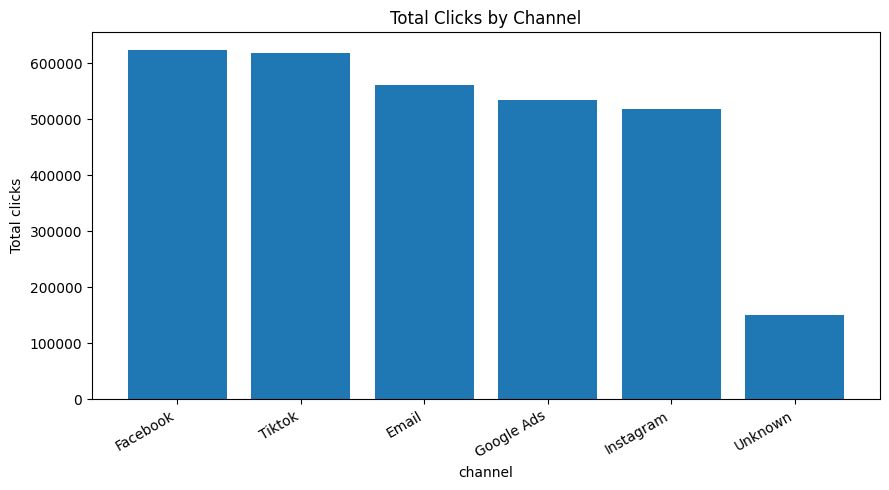

In [ ]:
#Visualizing Channel performance

plot_data = channel_performance.sort_values(
    "clicks", ascending = False
)

plt.figure(figsize=(9,5))
plt.bar(plot_data["channel"].astype(str), plot_data["clicks"])
plt.title("Total Clicks by Channel")
plt.xlabel("channel")
plt.ylabel("Total clicks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


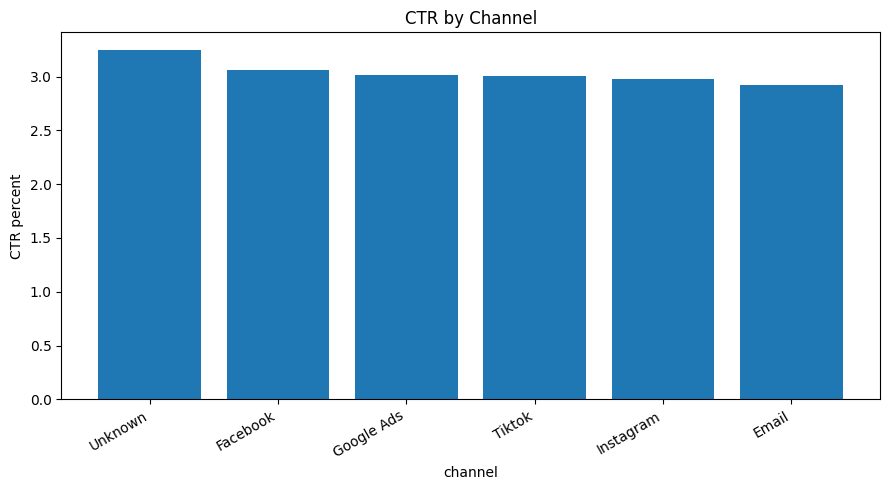

In [ ]:
# CTR by channel

plot_data = channel_performance.sort_values("ctr_pct", ascending=False)

plt.figure(figsize=(9,5))
plt.bar(plot_data["channel"].astype(str), plot_data["ctr_pct"])
plt.title("CTR by Channel")
plt.xlabel("channel")
plt.ylabel("CTR percent")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

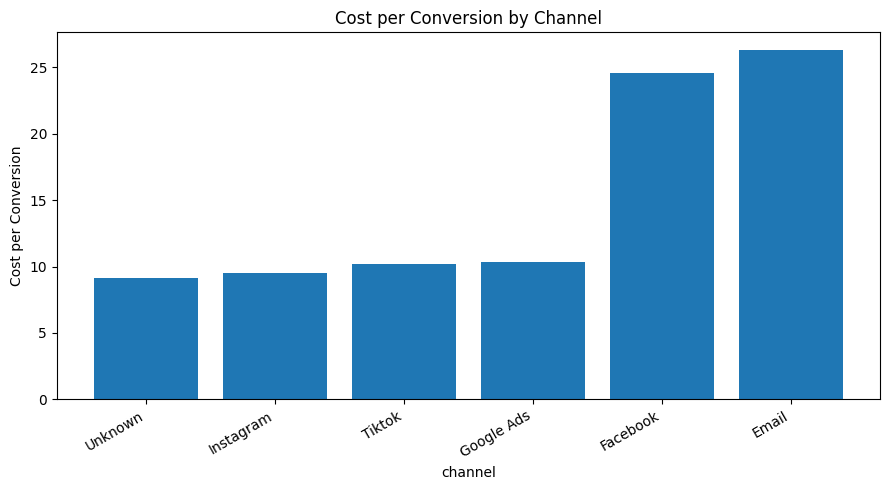

In [ ]:
#Cost per conversion by channel

plot_data = channel_performance.dropna(
    subset=["cost_per_conversion"]
).sort_values("cost_per_conversion")

plt.figure(figsize=(9,5))
plt.bar(
    plot_data["channel"].astype(str),
    plot_data["cost_per_conversion"]
)
plt.title("Cost per Conversion by Channel")
plt.xlabel("channel")
plt.ylabel("Cost per Conversion")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:

# Compare performance across campaign types

campaign_type_performance = (
    df_eda.groupby("campaign_type", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks_1", "sum"),
        conversions=("conversions", "sum"),
        campaigns_with_conversions=("conversions", "count"),
        clicks_for_conversion_rate=(
            "clicks_with_known_conversions", "sum"
        ),
        spend=("spend_analysis", "sum"),
        clicks_for_cpc=("clicks_with_valid_spend", "sum"),
        spend_for_cost_per_conversion=(
            "spend_with_known_conversions", "sum"
        ),
        conversions_for_cost_per_conversion=(
            "conversions_with_valid_spend", "sum"
        ),
        median_duration_days=("campaign_duration_days", "median")
    )
    .reset_index()
)

campaign_type_performance["ctr_pct"] = (
    campaign_type_performance["clicks"]
    / campaign_type_performance["impressions"].replace(0, np.nan)
    * 100
)

campaign_type_performance["conversion_rate_pct"] = (
    campaign_type_performance["conversions"]
    / campaign_type_performance["clicks_for_conversion_rate"].replace(
        0, np.nan
    )
    * 100
)

campaign_type_performance["cpc"] = (
    campaign_type_performance["spend"]
    / campaign_type_performance["clicks_for_cpc"].replace(0, np.nan)
)

campaign_type_performance["cost_per_conversion"] = (
    campaign_type_performance["spend_for_cost_per_conversion"]
    / campaign_type_performance[
        "conversions_for_cost_per_conversion"
    ].replace(0, np.nan)
)

display(
    campaign_type_performance.round(2).sort_values(
        "conversions", ascending=False
    )
)


,campaign_type,campaigns,impressions,clicks,conversions,campaigns_with_conversions,clicks_for_conversion_rate,spend,clicks_for_cpc,spend_for_cost_per_conversion,conversions_for_cost_per_conversion,median_duration_days,ctr_pct,conversion_rate_pct,cpc,cost_per_conversion
1,Launch,506,24496756,744030,86477.0,451,662560.0,1906544.97,735613.0,1308345.42,85704.0,15.0,3.04,13.05,2.59,15.27
3,Winter,512,25445867,767167,85047.0,463,684183.0,1443321.40,767167.0,1344342.16,85047.0,16.0,3.01,12.43,1.88,15.81
0,BlackFriday,503,25492225,763194,82282.0,451,673142.0,963778.01,759091.0,843987.04,81961.0,16.0,2.99,12.22,1.27,10.30
2,Summer,479,24265205,728084,81257.0,435,665236.0,1921164.98,721603.0,1842784.74,80568.0,15.0,3.00,12.21,2.66,22.87


In [ ]:
#Checking Active users V/s Inactive users


# Compare active and inactive campaigns

active_performance = (
    df_eda.groupby("active", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks_1", "sum"),
        conversions=("conversions", "sum"),
        campaigns_with_conversions=("conversions", "count"),
        clicks_for_conversion_rate=(
            "clicks_with_known_conversions", "sum"
        ),
        spend=("spend_analysis", "sum"),
        clicks_for_cpc=("clicks_with_valid_spend", "sum"),
        spend_for_cost_per_conversion=(
            "spend_with_known_conversions", "sum"
        ),
        conversions_for_cost_per_conversion=(
            "conversions_with_valid_spend", "sum"
        )
    )
    .reset_index()
)

active_performance["ctr_pct"] = (
    active_performance["clicks"]
    / active_performance["impressions"].replace(0, np.nan)
    * 100
)

active_performance["conversion_rate_pct"] = (
    active_performance["conversions"]
    / active_performance["clicks_for_conversion_rate"].replace(0, np.nan)
    * 100
)

active_performance["cpc"] = (
    active_performance["spend"]
    / active_performance["clicks_for_cpc"].replace(0, np.nan)
)

active_performance["cost_per_conversion"] = (
    active_performance["spend_for_cost_per_conversion"]
    / active_performance[
        "conversions_for_cost_per_conversion"
    ].replace(0, np.nan)
)

display(active_performance.round(2))


,active,campaigns,impressions,clicks,conversions,campaigns_with_conversions,clicks_for_conversion_rate,spend,clicks_for_cpc,spend_for_cost_per_conversion,conversions_for_cost_per_conversion,ctr_pct,conversion_rate_pct,cpc,cost_per_conversion
0,False,818,40985493,1228350,136452.0,736,1091612.0,3534280.51,1223224.0,2863767.61,135980.0,3.00,12.50,2.89,21.06
1,True,1182,58714560,1774125,198611.0,1064,1593509.0,2700528.85,1760250.0,2475691.75,197300.0,3.02,12.46,1.53,12.55


,spend_analysis
count,1981.000000
mean,3147.304069
std,25050.171115
min,10.010000
1%,34.526000
5%,149.770000
25%,659.420000
50%,1455.430000
75%,2653.780000
95%,5308.230000


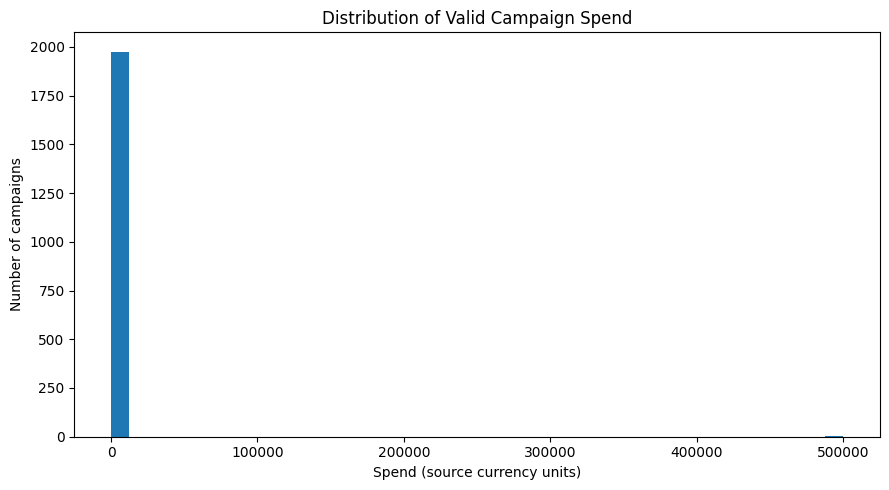

In [ ]:
#Summary stats and distribution


# Analyze the distribution of valid spend

spend_valid = df_eda["spend_analysis"].dropna()

display(
    spend_valid.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("spend_analysis")
)

plt.figure(figsize=(9, 5))
plt.hist(spend_valid, bins=40)
plt.title("Distribution of Valid Campaign Spend")
plt.xlabel("Spend (source currency units)")
plt.ylabel("Number of campaigns")
plt.tight_layout()
plt.show()


In [ ]:

# Use the IQR rule to identify high-spend records for review

q1 = spend_valid.quantile(0.25)
q3 = spend_valid.quantile(0.75)
iqr = q3 - q1

upper_fence = q3 + 1.5 * iqr

df_eda["high_spend_outlier_flag"] = (
    df_eda["spend_analysis"] > upper_fence
)

spend_outliers = df_eda.loc[
    df_eda["high_spend_outlier_flag"],
    [
        "campaign_id",
        "campaign_name",
        "channel",
        "spend",
        "spend_analysis"
    ]
].sort_values("spend_analysis", ascending=False)

print("Upper IQR fence:", round(upper_fence, 2))
print("High-spend records flagged:", len(spend_outliers))

display(spend_outliers.head(25))


Upper IQR fence: 5645.32
High-spend records flagged: 73


,campaign_id,campaign_name,channel,spend,spend_analysis
789,CMP-00790,Q2_Summer_CMP-00790,Facebook,500000.00,500000.00
1460,CMP-01461,Q4_Launch_CMP-01461,Facebook,500000.00,500000.00
1781,CMP-01782,Q1_Launch_CMP-01782,Email,500000.00,500000.00
1754,CMP-01755,Q1_Summer_CMP-01755,Email,500000.00,500000.00
1718,CMP-01719,Q1_Winter_CMP-01719,Email,500000.00,500000.00
1443,CMP-01444,Q1_Launch_CMP-01444,Google Ads,8921.51,8921.51
1925,CMP-01926,Q4_Winter_CMP-01926,Facebook,8269.90,8269.90
1358,CMP-01359,Q3_BlackFriday_CMP-01359,Tiktok,8267.84,8267.84
1449,CMP-01450,Q4_Summer_CMP-01450,Google Ads,8209.43,8209.43
189,CMP-00190,Q4_Summer_CMP-00190,Facebook,7777.24,7777.24


In [ ]:
# Summary of data coverage.


# Identify campaigns with valid start and end dates
valid_date_mask = (
    df_clean["start_date"].notna()
    & df_clean["end_date"].notna()
    & (df_clean["end_date"] >= df_clean["start_date"])
)

# Calculate duration only for valid date pairs
df_eda["campaign_duration_days"] = (
    df_eda["end_date"] - df_eda["start_date"]
).dt.days

df_eda["valid_duration_flag"] = valid_date_mask

valid_durations = df_eda.loc[
    df_eda["valid_duration_flag"],
    "campaign_duration_days"
]

date_coverage = pd.DataFrame({
    "metric": [
        "Earliest valid start date",
        "Latest valid start date",
        "Earliest valid end date",
        "Latest valid end date",
        "Campaigns with valid date pairs",
        "Campaigns with reversed dates",
        "Campaigns with missing start dates",
        "Campaigns with missing end dates",
        "Median valid campaign duration (days)"
    ],
    "value": [
        df_clean["start_date"].min(),
        df_clean["start_date"].max(),
        df_clean["end_date"].min(),
        df_clean["end_date"].max(),
        valid_date_mask.sum(),
        (
            df_clean["end_date"] < df_clean["start_date"]
        ).sum(),
        df_clean["start_date"].isna().sum(),
        df_clean["end_date"].isna().sum(),
        valid_durations.median()
    ]
})

display(date_coverage)


,metric,value
0,Earliest valid start date,2023-01-01 00:00:00
1,Latest valid start date,2024-01-01 00:00:00
2,Earliest valid end date,2022-12-31 00:00:00
3,Latest valid end date,2024-01-30 00:00:00
4,Campaigns with valid date pairs,1858
5,Campaigns with reversed dates,75
6,Campaigns with missing start dates,67
7,Campaigns with missing end dates,0
8,Median valid campaign duration (days),15.5


In [ ]:
#Comparing the durations by Campaign types

duration_by_type = (
    df_eda.loc[df_eda["valid_duration_flag"]]
    .groupby("campaign_type", dropna=False)["campaign_duration_days"]
    .agg(
        campaign_count="count",
        median_days="median",
        mean_days="mean",
        maximum_days="max"
    )
    .reset_index()
    .sort_values("median_days", ascending=False)
)

display(duration_by_type.round(2))


,campaign_type,campaign_count,median_days,mean_days,maximum_days
0,BlackFriday,467,16.0,16.66,285.0
3,Winter,466,16.0,18.99,258.0
1,Launch,484,15.0,16.41,278.0
2,Summer,441,15.0,16.22,239.0


,start_month,campaigns,impressions,clicks,conversions,campaigns_with_conversions,spend
0,2023-01-01,139,7042419,226080,24684.0,123,774674.35
1,2023-02-01,152,7299984,208407,23795.0,134,249492.30
2,2023-03-01,150,7317085,225237,25326.0,134,284278.52
3,2023-04-01,145,7319375,229596,26538.0,134,293216.51
4,2023-05-01,161,8138933,247370,27367.0,147,795735.53
5,2023-06-01,174,8959014,266890,30112.0,159,822546.19
6,2023-07-01,163,8609632,266879,29508.0,143,345291.75
7,2023-08-01,158,7202340,208157,23547.0,139,273540.07
8,2023-09-01,157,7680367,238371,26330.0,146,785079.59
9,2023-10-01,183,8550191,240642,26107.0,165,299228.04


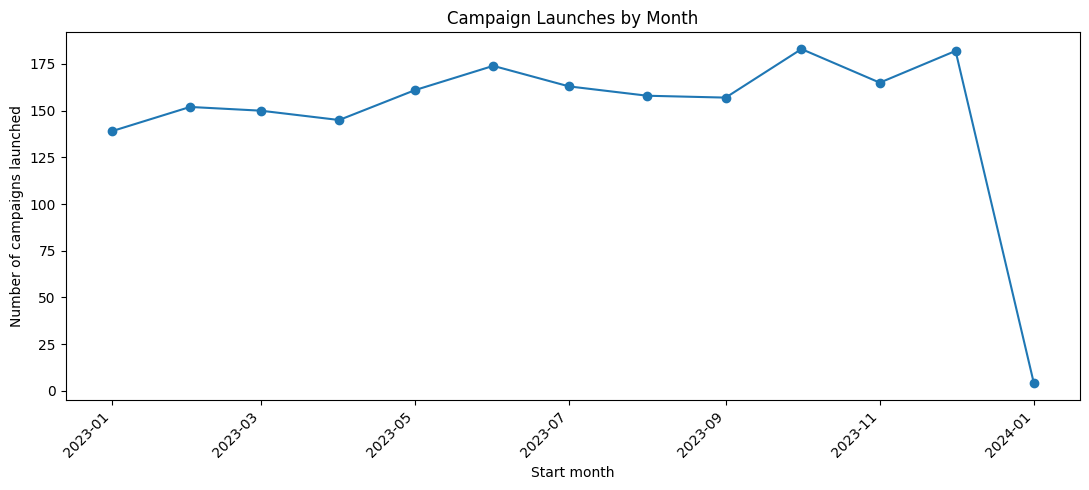

In [ ]:
#Analyzing campaigns by the month in which they started

monthly_launches = (
    df_eda.dropna(subset=["start_date"])
    .assign(
        start_month=lambda data:
            data["start_date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("start_month")
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks_1", "sum"),
        conversions=("conversions", "sum"),
        campaigns_with_conversions=("conversions", "count"),
        spend=("spend_analysis", "sum")
    )
    .reset_index()
    .sort_values("start_month")
)

display(monthly_launches)

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_launches["start_month"],
    monthly_launches["campaigns"],
    marker="o"
)
plt.title("Campaign Launches by Month")
plt.xlabel("Start month")
plt.ylabel("Number of campaigns launched")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# Summarize conversion missingness by channel

missing_conversion_by_channel = (
    df_eda.groupby("channel", dropna=False)
    .agg(
        campaigns=("campaign_id", "size"),
        missing_conversions=("conversion_missing_flag", "sum"),
        missing_rate=("conversion_missing_flag", "mean")
    )
    .reset_index()
)

missing_conversion_by_channel["missing_rate_pct"] = (
    missing_conversion_by_channel["missing_rate"] * 100
).round(2)

display(
    missing_conversion_by_channel.sort_values(
        "missing_rate_pct", ascending=False
    )
)


,channel,campaigns,missing_conversions,missing_rate,missing_rate_pct
3,Instagram,358,44,0.122905,12.29
2,Google Ads,354,35,0.098870,9.89
1,Facebook,401,39,0.097257,9.73
4,Tiktok,412,40,0.097087,9.71
0,Email,375,34,0.090667,9.07
5,Unknown,100,8,0.080000,8.00


In [ ]:

# Combine funnel and negative-count flags into one review table

funnel_anomaly_mask = (
    df_eda["clicks_gt_impressions_flag"]
    | df_eda["conversions_gt_clicks_flag"]
    | df_eda["negative_impressions_flag"]
    | df_eda["negative_clicks_flag"]
    | df_eda["negative_conversions_flag"]
)

funnel_anomaly_records = df_eda.loc[
    funnel_anomaly_mask,
    [
        "campaign_id",
        "campaign_name",
        "channel",
        "impressions",
        "clicks_1",
        "conversions",
        "clicks_gt_impressions_flag",
        "conversions_gt_clicks_flag",
        "negative_impressions_flag",
        "negative_clicks_flag",
        "negative_conversions_flag"
    ]
].copy()

print(
    "Campaigns with at least one funnel or negative-count anomaly:",
    len(funnel_anomaly_records)
)

display(funnel_anomaly_records.head(50))


Campaigns with at least one funnel or negative-count anomaly: 0


,campaign_id,campaign_name,channel,impressions,clicks_1,conversions,clicks_gt_impressions_flag,conversions_gt_clicks_flag,negative_impressions_flag,negative_clicks_flag,negative_conversions_flag


In [ ]:

# Summarize key data-quality checks

quality_checks = pd.DataFrame({
    "check": [
        "Rows in cleaned dataset",
        "Unique campaign IDs",
        "Missing channel values",
        "Missing conversion values",
        "Negative spend values",
        "Reversed date ranges",
        "Missing start dates",
        "Missing end dates",
        "Clicks greater than impressions",
        "Conversions greater than clicks",
        "Negative impressions",
        "Negative clicks",
        "Negative conversions"
    ],
    "records": [
        len(df_clean),
        df_clean["campaign_id"].nunique(),
        df_clean["channel"].isna().sum(),
        df_clean["conversions"].isna().sum(),
        (df_clean["spend"] < 0).sum(),
        (
            df_clean["end_date"] < df_clean["start_date"]
        ).sum(),
        df_clean["start_date"].isna().sum(),
        df_clean["end_date"].isna().sum(),
        df_clean["clicks_gt_impressions_flag"].sum(),
        df_clean["conversions_gt_clicks_flag"].sum(),
        df_clean["negative_impressions_flag"].sum(),
        df_clean["negative_clicks_flag"].sum(),
        df_clean["negative_conversions_flag"].sum()
    ]
})

display(quality_checks)


,check,records
0,Rows in cleaned dataset,2000
1,Unique campaign IDs,2000
2,Missing channel values,0
3,Missing conversion values,200
4,Negative spend values,19
5,Reversed date ranges,75
6,Missing start dates,67
7,Missing end dates,0
8,Clicks greater than impressions,0
9,Conversions greater than clicks,0


In [ ]:

# Export the cleaned dataset and analysis outputs

df_clean.to_csv(
    "marketing_campaign_cleaned_for_analysis.csv",
    index=False
)

quality_checks.to_csv(
    "marketing_campaign_data_quality_report.csv",
    index=False
)

channel_performance.to_csv(
    "marketing_campaign_eda_channel_performance.csv",
    index=False
)

campaign_type_performance.to_csv(
    "marketing_campaign_eda_campaign_type_performance.csv",
    index=False
)

active_performance.to_csv(
    "marketing_campaign_eda_active_performance.csv",
    index=False
)

monthly_launches.to_csv(
    "marketing_campaign_eda_monthly_launches.csv",
    index=False
)

missing_conversion_by_channel.to_csv(
    "marketing_campaign_missing_conversions_by_channel.csv",
    index=False
)

funnel_anomaly_records.to_csv(
    "marketing_campaign_funnel_anomalies.csv",
    index=False
)

spend_outliers.to_csv(
    "marketing_campaign_spend_outlier_review.csv",
    index=False
)

print("All requested analysis exports completed.")


All requested analysis exports completed.


#Validating the data cleaning and EDA

In [ ]:
print("Cleaned rows:", len(df_clean))
print("Unique campaign IDs:", df_clean["campaign_id"].nunique())
print(
    "Repeated campaign ID rows:",
    df_clean["campaign_id"].duplicated().sum()
)
print("Exact duplicate rows:", df_clean.duplicated().sum())

Cleaned rows: 2000
Unique campaign IDs: 2000
Repeated campaign ID rows: 0
Exact duplicate rows: 0


In [ ]:
#Checking missing values

missing_report = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_pct": (
        df_clean.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "missing_count", ascending=False
    )
)

,missing_count,missing_pct
conversions,200,10.00
campaign_duration_days,142,7.10
start_date,67,3.35
spend_analysis,19,0.95
campaign_name,0,0.00
campaign_id,0,0.00
impressions,0,0.00
clicks_1,0,0.00
spend,0,0.00
channel,0,0.00


In [ ]:
#Checking if negative spend were excluded from the analysis

print("Negative original spend:",
      (df_clean["spend"] < 0).sum())

print("Missing spend_clean:",
      df_clean["spend_analysis"].isna().sum())

print("Negative spend_clean:",
      (df_clean["spend_analysis"] < 0).sum())

print("Valid non-negative spend:",
      df_clean["spend_analysis"].notna().sum())

Negative original spend: 19
Missing spend_clean: 19
Negative spend_clean: 0
Valid non-negative spend: 1981


In [ ]:
#Validating Funnel logic

print(
    "Clicks greater than impressions:",
    (df_clean["clicks_1"] > df_clean["impressions"]).sum()
)

print(
    "Conversions greater than clicks:",
    (
        df_clean["conversions"].notna()
        & (df_clean["conversions"] > df_clean["clicks_1"])
    ).sum()
)

print(
    "Negative clicks:",
    (df_clean["clicks_1"] < 0).sum()
)

print(
    "Negative conversions:",
    (df_clean["conversions"] < 0).sum()
)

Clicks greater than impressions: 0
Conversions greater than clicks: 0
Negative clicks: 0
Negative conversions: 0


In [ ]:
#Checking if columns are correctly standardized

print("Channel values:")
print(sorted(df_clean["channel"].astype(str).unique()))

print("\nCampaign types:")
print(sorted(df_clean["campaign_type"].astype(str).unique()))

print("\nActive values:")
print(sorted(df_clean["active"].astype(str).unique()))

Channel values:
['Email', 'Facebook', 'Google Ads', 'Instagram', 'Tiktok', 'Unknown']

Campaign types:
['BlackFriday', 'Launch', 'Summer', 'Winter']

Active values:
['False', 'True']


In [ ]:
# Working on a copy so the cleaned dataset is not changed.
kpi_data = df_clean.copy()

# Eligibility flags
kpi_data["valid_clicks"] = (
    kpi_data["clicks_1"].notna()
    & (kpi_data["clicks_1"] >= 0)
)

kpi_data["valid_impressions"] = (
    kpi_data["impressions"].notna()
    & (kpi_data["impressions"] > 0)
)

kpi_data["valid_spend"] = (
    kpi_data["spend_analysis"].notna()
    & (kpi_data["spend_analysis"] >= 0)
)

kpi_data["known_conversions"] = (
    kpi_data["conversions"].notna()
    & (kpi_data["conversions"] >= 0)
)

# Records eligible for each KPI
kpi_data["eligible_ctr"] = (
    kpi_data["valid_clicks"]
    & kpi_data["valid_impressions"]
)

kpi_data["eligible_cvr"] = (
    kpi_data["valid_clicks"]
    & kpi_data["known_conversions"]
)

kpi_data["eligible_cpc"] = (
    kpi_data["valid_clicks"]
    & (kpi_data["clicks_1"] > 0)
    & kpi_data["valid_spend"]
)

kpi_data["eligible_cpa"] = (
    kpi_data["valid_spend"]
    & kpi_data["known_conversions"]
)

# Helper columns: values are included only for eligible records
kpi_data["ctr_clicks"] = kpi_data["clicks_1"].where(
    kpi_data["eligible_ctr"]
)
kpi_data["ctr_impressions"] = kpi_data["impressions"].where(
    kpi_data["eligible_ctr"]
)

kpi_data["cvr_conversions"] = kpi_data["conversions"].where(
    kpi_data["eligible_cvr"]
)
kpi_data["cvr_clicks"] = kpi_data["clicks_1"].where(
    kpi_data["eligible_cvr"]
)

kpi_data["cpc_spend"] = kpi_data["spend_analysis"].where(
    kpi_data["eligible_cpc"]
)
kpi_data["cpc_clicks"] = kpi_data["clicks_1"].where(
    kpi_data["eligible_cpc"]
)

kpi_data["cpa_spend"] = kpi_data["spend_analysis"].where(
    kpi_data["eligible_cpa"]
)
kpi_data["cpa_conversions"] = kpi_data["conversions"].where(
    kpi_data["eligible_cpa"]
)

# Aggregate at channel level
validated_channels = (
    kpi_data.groupby("channel", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        eligible_ctr_rows=("eligible_ctr", "sum"),
        eligible_cvr_rows=("eligible_cvr", "sum"),
        eligible_cpc_rows=("eligible_cpc", "sum"),
        eligible_cpa_rows=("eligible_cpa", "sum"),
        clicks_ctr=("ctr_clicks", "sum"),
        impressions_ctr=("ctr_impressions", "sum"),
        conversions_cvr=("cvr_conversions", "sum"),
        clicks_cvr=("cvr_clicks", "sum"),
        spend_cpc=("cpc_spend", "sum"),
        clicks_cpc=("cpc_clicks", "sum"),
        spend_cpa=("cpa_spend", "sum"),
        conversions_cpa=("cpa_conversions", "sum")
    )
    .reset_index()
)

validated_channels["ctr_pct"] = (
    validated_channels["clicks_ctr"]
    / validated_channels["impressions_ctr"]
    * 100
)

validated_channels["conversion_rate_pct"] = (
    validated_channels["conversions_cvr"]
    / validated_channels["clicks_cvr"]
    * 100
)

validated_channels["cpc"] = (
    validated_channels["spend_cpc"]
    / validated_channels["clicks_cpc"]
)

validated_channels["cost_per_conversion"] = (
    validated_channels["spend_cpa"]
    / validated_channels["conversions_cpa"].replace(0, np.nan)
)

display(validated_channels.round(2))

,channel,campaigns,eligible_ctr_rows,eligible_cvr_rows,eligible_cpc_rows,eligible_cpa_rows,clicks_ctr,impressions_ctr,conversions_cvr,clicks_cvr,spend_cpc,clicks_cpc,spend_cpa,conversions_cpa,ctr_pct,conversion_rate_pct,cpc,cost_per_conversion
0,Email,375,375,341,373,339,560082,19156770,62632.0,514661.0,2197742.66,558276.0,1645116.35,62493.0,2.92,12.17,3.94,26.32
1,Facebook,401,401,362,394,355,623589,20395140,69502.0,555359.0,1776485.52,615438.0,1684259.72,68587.0,3.06,12.51,2.89,24.56
2,Google Ads,354,354,319,351,316,533706,17646113,60384.0,479628.0,682094.12,529806.0,618660.20,60014.0,3.02,12.59,1.29,10.31
3,Instagram,358,358,314,357,313,517158,17331450,57088.0,443690.0,635386.13,516682.0,540224.21,57009.0,2.98,12.87,1.23,9.48
4,Tiktok,412,412,372,408,368,617274,20528411,67713.0,552222.0,770686.97,614027.0,688530.48,67435.0,3.01,12.26,1.26,10.21
5,Unknown,100,100,92,98,91,150666,4642169,17744.0,139561.0,172413.96,149245.0,162685.75,17742.0,3.25,12.71,1.16,9.17


Campaigns included: 1800
Total clicks: 2685121
Total conversions: 335063.0


,channel,campaign_type,campaigns,total_clicks,total_conversions,conversion_rate_pct
21,Unknown,Launch,17,24960,3415.0,13.68
9,Google Ads,Launch,87,135310,18180.0,13.44
22,Unknown,Summer,32,45908,6113.0,13.32
14,Instagram,Summer,75,100437,13352.0,13.29
13,Instagram,Launch,80,107796,14182.0,13.16
5,Facebook,Launch,86,129020,16954.0,13.14
7,Facebook,Winter,94,142751,18683.0,13.09
1,Email,Launch,83,122679,15798.0,12.88
11,Google Ads,Winter,85,126487,16116.0,12.74
12,Instagram,BlackFriday,85,137298,17429.0,12.69


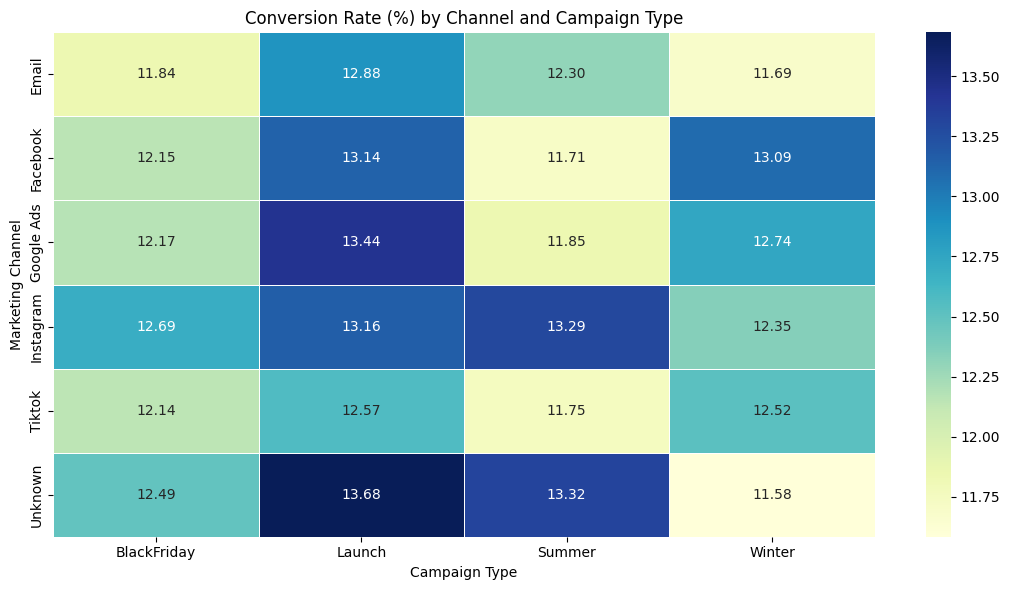

,active,campaigns,total_clicks,total_conversions,conversion_rate_pct
0,False,736,1091612,136452.0,12.50
1,True,1064,1593509,198611.0,12.46


,channel,campaign_type,active,campaigns,total_clicks,total_conversions,conversion_rate_pct
0,Email,BlackFriday,False,29,41155,4965.0,12.06
1,Email,BlackFriday,True,55,75186,8815.0,11.72
2,Email,Launch,False,22,42410,5412.0,12.76
3,Email,Launch,True,61,80269,10386.0,12.94
4,Email,Summer,False,34,49255,6406.0,13.01
5,Email,Summer,True,48,86479,10292.0,11.90
6,Email,Winter,False,36,58724,6861.0,11.68
7,Email,Winter,True,56,81183,9495.0,11.70
8,Facebook,BlackFriday,False,48,81492,10459.0,12.83
9,Facebook,BlackFriday,True,46,66459,7520.0,11.32


ValueError: negative dimensions are not allowed

In [ ]:

# ============================================================
# 1. PREPARE DATA FOR CONVERSION RATE ANALYSIS
# ============================================================

# Use the existing KPI analysis DataFrame.
analysis_df = df_eda.copy()

# Keep records with valid funnel metrics and known conversions.
valid_analysis = (
    analysis_df["impressions"].notna()
    & analysis_df["impressions"].ge(0)
    & analysis_df["clicks_1"].notna()
    & analysis_df["clicks_1"].gt(0)
    & analysis_df["conversions"].notna()
    & analysis_df["conversions"].ge(0)
    & analysis_df["conversions"].le(analysis_df["clicks_1"])
    & analysis_df["clicks_1"].le(analysis_df["impressions"])
    & analysis_df["channel"].notna()
    & analysis_df["campaign_type"].notna()
)

analysis_df = analysis_df.loc[valid_analysis].copy()

# Calculate conversion rate for this eligible population.
analysis_df["conversion_rate"] = (
    analysis_df["conversions"] / analysis_df["clicks_1"]
)

print("Campaigns included:", len(analysis_df))
print("Total clicks:", analysis_df["clicks_1"].sum())
print("Total conversions:", analysis_df["conversions"].sum())


# ============================================================
# 2. CONVERSION RATE BY CHANNEL AND CAMPAIGN TYPE
# ============================================================

channel_type_performance = (
    analysis_df
    .groupby(["channel", "campaign_type"])
    .agg(
        campaigns=("campaign_id", "nunique"),
        total_clicks=("clicks_1", "sum"),
        total_conversions=("conversions", "sum")
    )
    .reset_index()
)

# Aggregate conversion rate
channel_type_performance["conversion_rate_pct"] = (
    channel_type_performance["total_conversions"]
    / channel_type_performance["total_clicks"]
    * 100
)

channel_type_performance = channel_type_performance.sort_values(
    "conversion_rate_pct",
    ascending=False
)

display(channel_type_performance.round(2))


# ============================================================
# 3. VISUALIZE CHANNEL VS CAMPAIGN TYPE
# ============================================================

conversion_heatmap = channel_type_performance.pivot(
    index="channel",
    columns="campaign_type",
    values="conversion_rate_pct"
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    conversion_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Conversion Rate (%) by Channel and Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()


# ============================================================
# 4. ACTIVE VS INACTIVE CAMPAIGN PERFORMANCE
# ============================================================

active_performance = (
    analysis_df
    .groupby("active", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        total_clicks=("clicks_1", "sum"),
        total_conversions=("conversions", "sum")
    )
    .reset_index()
)

active_performance["conversion_rate_pct"] = (
    active_performance["total_conversions"]
    / active_performance["total_clicks"]
    * 100
)

display(active_performance.round(2))


# ============================================================
# 5. ACTIVE STATUS WITHIN CHANNEL AND CAMPAIGN TYPE
# ============================================================

active_by_channel_type = (
    analysis_df
    .groupby(
        ["channel", "campaign_type", "active"],
        dropna=False
    )
    .agg(
        campaigns=("campaign_id", "nunique"),
        total_clicks=("clicks_1", "sum"),
        total_conversions=("conversions", "sum")
    )
    .reset_index()
)

active_by_channel_type["conversion_rate_pct"] = (
    active_by_channel_type["total_conversions"]
    / active_by_channel_type["total_clicks"]
    * 100
)

display(active_by_channel_type.round(2))


# ============================================================
# 6. STATISTICAL MODEL: ASSOCIATIONS
# ============================================================

# Exclude Unknown active status from this comparison.
model_df = analysis_df[
    analysis_df["active"].isin(["True", "False"])
].copy()

# Use categorical predictors.
model_df["channel"] = model_df["channel"].astype("category")
model_df["campaign_type"] = model_df["campaign_type"].astype("category")
model_df["active"] = model_df["active"].astype("category")

# Binomial GLM:
# Campaign conversion rate is weighted by its click count.
formula = (
    "conversion_rate ~ "
    "C(channel) * C(campaign_type) + C(active)"
)

model = smf.glm(
    formula=formula,
    data=model_df,
    family=sm.families.Binomial(),
    var_weights=model_df["clicks_1"]
).fit()

print(model.summary())


# ============================================================
# 7. EXPORT RESULTS
# ============================================================

with pd.ExcelWriter(
    "Marketing_Campaign_Conversion_Analysis.xlsx"
) as writer:

    channel_type_performance.to_excel(
        writer,
        sheet_name="Channel_Campaign_Type",
        index=False
    )

    active_performance.to_excel(
        writer,
        sheet_name="Active_Performance",
        index=False
    )

    active_by_channel_type.to_excel(
        writer,
        sheet_name="Active_by_Channel_Type",
        index=False
    )

    pd.DataFrame({
        "coefficient": model.params,
        "p_value": model.pvalues
    }).to_excel(
        writer,
        sheet_name="Statistical_Model"
    )

print("Conversion analysis completed.")

In [ ]:
campaign_type_analysis = (
    df_eda
    .groupby("campaign_type")
    .agg(
        total_campaigns=("campaign_id", "nunique"),
        total_clicks=("clicks_1", "sum"),
        total_conversions=("conversions", "sum")
    )
    .reset_index()
)

campaign_type_analysis["conversion_rate"] = (
    campaign_type_analysis["total_conversions"]
    / campaign_type_analysis["total_clicks"]
) * 100

campaign_type_analysis = campaign_type_analysis.sort_values(
    by="conversion_rate",
    ascending=False
)

display(campaign_type_analysis)

## Executive Summary - Marketing Campaign Performance Analysis

### 1. Project objective

The objective of this project was to assess marketing campaign performance across channels, campaign types and active status; understand engagement and conversion patterns; examine spend distribution and campaign timing; and identify data-quality limitations that could affect business reporting.

The analysis followed an evidence-based workflow: profile the original data, clean and standardize fields, preserve unresolved values for audit, calculate campaign KPIs, aggregate performance metrics, and validate the resulting summaries.

After duplicate handling and campaign ID resolution, the dataset contained **2,000 unique campaigns**.

### 2. Channel performance

**Which channel generated the most clicks?**

Facebook generated the most clicks, with **623,589 clicks** across 401 campaigns. TikTok followed with 617,274 clicks across 412 campaigns. Facebook therefore had the highest recorded click volume, although its lead over TikTok was relatively small.

**Which channel had the highest aggregate CTR?**

Among the named marketing channels, Facebook recorded the highest aggregate click-through rate (CTR) at **3.06%**.

The Unknown channel group recorded 3.25%, but these 100 campaigns lack a reliably identified channel. This group should be investigated separately rather than treated as a marketing channel for budget-allocation decisions.

**Which channel had the highest aggregate conversion rate?**

Among the named channels, Google Ads had the highest aggregate conversion rate at **11.31%**, followed by Email at 11.18% and Facebook at 11.15%.

The Unknown group recorded 11.78%, but its channel identity is unresolved. This result should not be used to select a marketing channel without investigating the underlying records.

**Which channel had the lowest cost per conversion?**

Among the named channels, Instagram had the lowest recorded cost per conversion at **11.13 spend units per recorded conversion**, followed by Google Ads at 11.30 and TikTok at 11.38.

Email had the highest recorded cost per conversion at 35.09, followed by Facebook at 25.56. These values are provisional because the source data does not establish whether spend values are comparable across currencies.

**Are the differences meaningful when campaign volume and conversion-data completeness are considered?**

The main channels had broadly similar campaign volumes, ranging from 354 Google Ads campaigns to 412 TikTok campaigns. Conversion values were available for:

- Facebook: 362 of 401 campaigns (90.27%)
- TikTok: 372 of 412 campaigns (90.29%)
- Email: 341 of 375 campaigns (90.93%)
- Google Ads: 319 of 354 campaigns (90.11%)
- Instagram: 314 of 358 campaigns (87.71%)

Instagram had the highest missing-conversion rate among the named channels, at 12.29%. This limits confidence in comparisons involving its conversion rate and cost per conversion.

These are descriptive differences, not evidence of statistical significance or incremental campaign impact. The analysis does not establish whether the observed differences would persist after accounting for campaign objectives, audience composition, attribution, or other factors.

### 3. Campaign type and status

**Which campaign type generated the most recorded conversions?**

Launch campaigns generated the most recorded conversions, with **86,477 conversions across 506 campaigns**.

The remaining campaign types recorded:

- Winter: 85,047 conversions across 512 campaigns
- BlackFriday: 82,282 conversions across 503 campaigns
- Summer: 81,257 conversions across 479 campaigns

**How did CTR, conversion rate and cost per conversion differ across campaign types?**

| Campaign type | Aggregate CTR | Aggregate conversion rate | Cost per recorded conversion |
|---|---:|---:|---:|
| Launch | 3.04% | 11.62% | 22.05 |
| Winter | 3.01% | 11.09% | 16.97 |
| BlackFriday | 2.99% | 10.78% | 11.71 |
| Summer | 3.00% | 11.16% | 23.64 |

Launch campaigns had the highest CTR and conversion rate and generated the most recorded conversions. However, BlackFriday campaigns had the lowest cost per recorded conversion. Summer campaigns had the highest cost per recorded conversion.

This suggests that engagement, conversion volume and cost efficiency do not necessarily identify the same best-performing campaign type. The results do not prove that campaign type alone caused these differences.

**Did active and inactive campaign groups show different aggregate performance?**

The notebook's status summary recorded the following results:

| Metric | Active (Yes) | Inactive (No) |
|---|---:|---:|
| Campaigns | 1,182 | 818 |
| Clicks | 1,774,125 | 1,228,350 |
| Recorded conversions | 198,611 | 136,452 |
| Aggregate CTR | 3.02% | 3.00% |
| Aggregate conversion rate | 11.19% | 11.11% |
| Cost per recorded conversion | 13.60 | 25.90 |

The active group had more campaigns, clicks and recorded conversions, along with a slightly higher aggregate CTR and conversion rate and a lower cost per recorded conversion.

However, active and inactive campaigns may differ in their duration, objectives, budgets and lifecycle stage. These are descriptive comparisons and do not demonstrate that active status itself caused better performance.

### 4. Spend and timing

**What does the spend distribution tell us about typical campaign spend?**

For the 1,981 campaigns with successfully parsed, non-negative spend, the median spend was **1,455.43**, while the mean was **3,147.30**.

The mean being substantially higher than the median, together with a maximum of 500,000, indicates a strongly right-skewed spend distribution. Most campaigns had considerably lower spend than the average, while a small number of high-spend records pulled the mean upward.

The 95th percentile was 5,308.23. These amounts are expressed in source spend units because currency comparability has not been established.

**How many unusually high-spend campaigns were flagged for investigation?**

The interquartile-range (IQR) method identified **73 campaigns** above the upper fence of 5,645.32.

Five records had spend values of 500,000, making them particularly important to verify. However, an IQR outlier is an investigation candidate, not automatically an error. These records should be checked against source transactions, currency conventions and campaign budgets before any exclusion decision is made.

**What patterns appear in monthly campaign launches and valid campaign duration?**

Campaign launches were most numerous in October and December 2023, with **186 campaigns in each month**. June recorded 182 launches. January 2024 recorded only six campaigns.

The recorded launch period runs from January 2023 through January 2024. The low count in January 2024 may reflect incomplete coverage of that month rather than a genuine decline in campaign activity.

Among the 1,922 campaigns with valid, non-negative durations, the median duration was **16 days**. Median duration was 16 days for BlackFriday and Winter campaigns and 15 days for Launch and Summer campaigns.

There were 78 campaigns whose end dates preceded their start dates. Their durations should not be treated as valid. Monthly launch counts describe recorded start dates and should be interpreted cautiously until unresolved date anomalies are reviewed.

### 5. Data-quality limitations

- **Missing conversions:** 200 campaigns (10.00% of the 2,000-campaign dataset) have missing conversion values. These represent unknown outcomes, not confirmed zero conversions. Conversion-related metrics may therefore be incomplete or biased.
- **Unknown channels:** 100 campaigns remain classified as Unknown after standardizing channel values. Their source records should be reviewed before making channel-specific recommendations.
- **Negative spend:** 19 negative spend values were retained in the audit fields and excluded from spend-based analytical calculations. Their meaning should be confirmed with the source-data owner.
- **Date anomalies:** 78 campaigns have end dates earlier than start dates. These records were flagged rather than assumed to have corrected dates. Their original dates should be verified before production duration reporting.
- **Currency comparability:** The source does not establish whether all spend values use the same currency or unit. Cost comparisons remain provisional until this is confirmed.
- **High-spend outliers:** 73 campaigns exceeded the IQR upper fence. These values require investigation rather than automatic removal.
- **Funnel consistency:** The notebook's saved checks reported zero campaigns with the tested funnel or negative-count anomalies. This is a positive result for those specific checks, but it does not establish that every source record is correct.
- **Interpretation:** The analysis is descriptive. It does not establish causality, statistical significance or incremental marketing lift.

### 6. Recommendations

1. **Validate conversion tracking.** Investigate the 200 missing